# Person 1 · Notebook 1 — Setup and PEMSD4 reproduction

**What this notebook does**
1. Sets up a shared `CS637/` folder on Google Drive with the authors' code and the PEMSD4 data.
2. **Smoke test:** evaluates one shipped checkpoint and checks it against the authors' own training log.
3. Evaluates all six PEMSD4 checkpoints (Quantile and MAEMIS trios). No training.
4. Computes 15, 30 and 60 minute metrics plus interval coverage, and compares them with Table 1 of the paper.
5. Saves validation and test predictions as `.npz` for Person 3.

**Before you start:** Runtime → Change runtime type → **T4 GPU**. Then Runtime → Run all.
The first run takes about 20–30 minutes, mostly cloning and data processing. Later runs skip finished steps.

If a cell fails, copy the full error into your Claude chat.

## 0. Drive and settings

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, glob, re, subprocess
BASE   = '/content/drive/MyDrive/CS637'          # shared team folder
AUTH   = f'{BASE}/uq4phy_traffic_network'        # authors' repo (never edited)
RAW    = f'{BASE}/data/raw'
OUT4   = f'{BASE}/outputs/pemsd4'                # prediction files for Person 3
P1     = f'{BASE}/p1'                            # our scripts and results (goes to reproduction/ in Git later)
DATA4  = '/content/pemsd4'                       # processed PEMSD4 on Colab's fast local disk (rebuilt each session)
for d in [RAW, OUT4, f'{P1}/scripts', f'{P1}/results', f'{P1}/logs']:
    os.makedirs(d, exist_ok=True)

MODELS = {   # short name -> authors' folder
    'Quantile':          'quantile_model_PEMSD4',
    'GPDE+Quantile':     'gpde_quantile_model_PEMSD4',
    'GPDE+Quantile+Phy': 'gpde_quantile_phy_model_PEMSD4',
    'MAEMIS':            'maemis_model_PEMSD4',
    'GPDE+MAEMIS':       'gpde_maemis_model_PEMSD4',
    'GPDE+MAEMIS+Phy':   'gpde_maemis_phy_model_PEMSD4_0.005',
}
PEMSD8_TRIO = ['quantile_model_PEMSD8', 'gpde_quantile_model_PEMSD8', 'gpde_quantile_phy_model_PEMSD8']  # for notebook 2
print('BASE =', BASE)

Mounted at /content/drive
BASE = /content/drive/MyDrive/CS637


In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch, numpy, scipy, yaml
print('torch', torch.__version__, '| cuda', torch.cuda.is_available(), '| numpy', numpy.__version__,
      '| scipy', scipy.__version__, '| pyyaml', yaml.__version__, '| python', sys.version.split()[0])
assert torch.cuda.is_available(), 'No GPU: Runtime -> Change runtime type -> T4 GPU'

name, memory.total [MiB]
Tesla T4, 15360 MiB
torch 2.11.0+cu130 | cuda True | numpy 2.1.3 | scipy 1.16.3 | pyyaml 6.0.3 | python 3.13.15


## 1. Authors' code

The full repo is about 1.2 GB with ~100 variant folders, so we clone **only the folders we need**: the six PEMSD4 variants and the PEMSD8 trio for notebook 2.
To add folders later (for Persons 2 and 3), run `git sparse-checkout add /<folder>/` inside `AUTH`.

In [ ]:
folders = list(MODELS.values()) + PEMSD8_TRIO
if not os.path.exists(f'{AUTH}/.git'):
    !git clone --filter=blob:none --no-checkout https://github.com/tianshubao1/uq4phy_traffic_network.git "{AUTH}"
    !git -C "{AUTH}" sparse-checkout set --no-cone {' '.join('/'+f+'/' for f in folders)}
    !git -C "{AUTH}" checkout
else:
    print('already cloned')
!git -C "{AUTH}" log -1 --format="authors' repo at commit %h (%cs)"
for f in folders:
    ckpts = sorted(glob.glob(f'{AUTH}/{f}/models/epo*.tar'))
    print(f'{f:40s} {len(ckpts):2d} checkpoints')

already cloned
authors' repo at commit 7d41f27 (2026-05-24)
quantile_model_PEMSD4                     9 checkpoints
gpde_quantile_model_PEMSD4               13 checkpoints
gpde_quantile_phy_model_PEMSD4            8 checkpoints
maemis_model_PEMSD4                      10 checkpoints
gpde_maemis_model_PEMSD4                 10 checkpoints
gpde_maemis_phy_model_PEMSD4_0.005       16 checkpoints
quantile_model_PEMSD8                     0 checkpoints
gpde_quantile_model_PEMSD8                0 checkpoints
gpde_quantile_phy_model_PEMSD8            0 checkpoints


In [ ]:
ROOT = '/content/drive/MyDrive/CS637'
!ls $ROOT
!ls $ROOT/data/raw
!ls $ROOT/uq4phy_traffic_network

data  outputs  p1  p2  uq4phy_traffic_network
pems04.npz
gpde_maemis_model_PEMSD4	    gpde_quantile_phy_model_PEMSD8
gpde_maemis_phy_model_PEMSD4_0.005  maemis_model_PEMSD4
gpde_quantile_model_PEMSD4	    quantile_model_PEMSD4
gpde_quantile_model_PEMSD8	    quantile_model_PEMSD8
gpde_quantile_phy_model_PEMSD4


In [ ]:
import os, requests
LOCAL = '/content/data'
failed = []

for name, article_id in {'PEMSD8': 28347662, 'METR-LA': 28347830}.items():
    out_dir = f'{LOCAL}/{name}'
    os.makedirs(out_dir, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{article_id}').json()['files']:
        path = f"{out_dir}/{f['name']}"
        if os.path.exists(path) and os.path.getsize(path) == f['size']:
            print('already have', name, f['name']); continue
        print('downloading', name, f['name'], round(f['size']/1e6, 1), 'MB')
        try:
            r = requests.get(f['download_url'], stream=True, timeout=120,
                             headers={'User-Agent': 'Mozilla/5.0'})
            r.raise_for_status()
            with open(path, 'wb') as out:
                for chunk in r.iter_content(1 << 20):
                    out.write(chunk)
        except Exception as e:
            print('   FAILED:', e); failed.append((name, f['name']))

print('\nFailed:', failed)
!ls -lh /content/data/PEMSD8 /content/data/METR-LA

downloading PEMSD8 train.npz 610.8 MB
downloading PEMSD8 PEMSD8 data processing.py 0.0 MB
downloading PEMSD8 pems8ndy.npy 72.9 MB
downloading PEMSD8 val.npz 86.3 MB
downloading PEMSD8 test.npz 173.8 MB
downloading METR-LA test.npz 72.4 MB
downloading METR-LA train.npz 264.0 MB
downloading METR-LA val.npz 37.4 MB

Failed: []
/content/data/METR-LA:
total 357M
-rw-r--r-- 1 root root  70M Oct 21 08:10 test.npz
-rw-r--r-- 1 root root 252M Oct 21 08:10 train.npz
-rw-r--r-- 1 root root  36M Oct 21 08:10 val.npz

/content/data/PEMSD8:
total 901M
-rw-r--r-- 1 root root  70M Oct 21 08:09  pems8ndy.npy
-rw-r--r-- 1 root root 3.0K Oct 21 08:09 'PEMSD8 data processing.py'
-rw-r--r-- 1 root root 166M Oct 21 08:10  test.npz
-rw-r--r-- 1 root root 583M Oct 21 08:09  train.npz
-rw-r--r-- 1 root root  83M Oct 21 08:10  val.npz


In [ ]:
import numpy as np
for ds in ['PEMSD8', 'METR-LA']:
    for split in ['train', 'val', 'test']:
        d = np.load(f'/content/data/{ds}/{split}.npz')
        print(ds, split, {k: d[k].shape for k in d.files})

PEMSD8 train {'x': (12476, 12, 170, 3), 'y': (12476, 12, 170, 3)}
PEMSD8 val {'x': (1762, 12, 170, 3), 'y': (1762, 12, 170, 3)}
PEMSD8 test {'x': (3549, 12, 170, 3), 'y': (3549, 12, 170, 3)}
METR-LA train {'x': (23974, 12, 207, 2), 'y': (23974, 12, 207, 2), 'x_offsets': (12, 1), 'y_offsets': (12, 1)}
METR-LA val {'x': (3425, 12, 207, 2), 'y': (3425, 12, 207, 2), 'x_offsets': (12, 1), 'y_offsets': (12, 1)}
METR-LA test {'x': (6850, 12, 207, 2), 'y': (6850, 12, 207, 2), 'x_offsets': (12, 1), 'y_offsets': (12, 1)}


In [ ]:
import numpy as np
for ds in ['PEMSD8', 'METR-LA']:
    x = np.load(f'/content/data/{ds}/train.npz')['x']
    print(ds)
    for i in range(x.shape[-1]):
        f = x[..., i]
        print(f'  feature {i}: min {f.min():.3f}  mean {f.mean():.3f}  max {f.max():.3f}')

# METR-LA: is feature 1 the same for every sensor at a given time step?
x = np.load('/content/data/METR-LA/train.npz')['x']
print('METR-LA feature 1 identical across all sensors:',
      np.allclose(x[..., 1], x[..., :1, 1]))

!cat "/content/data/PEMSD8/PEMSD8 data processing.py"

PEMSD8
  feature 0: min 3.000  mean 63.780  max 81.100
  feature 1: min 0.000  mean 0.065  max 0.896
  feature 2: min 0.000  mean 230.220  max 1147.000
METR-LA
  feature 0: min 0.000  mean 54.406  max 70.000
  feature 1: min 0.000  mean 0.497  max 0.997
METR-LA feature 1 identical across all sensors: True
# -*- coding: utf-8 -*-
"""
Created on Mon Aug 14 17:31:20 2023

@author: tians
"""



import numpy as np
# from matplotlib import pyplot as plt



dataset = np.load('pems8ndy.npy' )  #speed, occupancy, flow
# adj_matrix = np.load('pemsd8_adj_matrix.npy' )  
# adj_matrix = np.exp(adj_matrix/1609.344)
# adj_matrix = 1/adj_matrix
# np.save('PEMSD8_matrix.npy', adj_matrix)



# train = dataset[:int(17856*0.7),:,:2]   #[12499,170,2]
train = dataset[:int(17856*0.7),:,:]   #[12499,170,3]
# train_x = train[:-12,:,:]   #[12487,170,2]      META-LA:[23974, 12, 207, 2]
# train_y = train[12:,:,:]    #[12487,170,2]
train_x = np.zeros([12476,12,170,3])        #[11:12487], remove the first 11 and la

In [ ]:
ROOT = '/content/drive/MyDrive/CS637'
%cd $ROOT/uq4phy_traffic_network
!git sparse-checkout add gpde_quantile_model gpde_quantile_phy_model
!ls

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/uq4phy_traffic_network
Updating index flags: 100% (4544/4544), done.
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 12 (delta 5), reused 2 (delta 2), pack-reused 2 (from 1)
Receiving objects: 100% (12/12), 38.94 KiB | 531.00 KiB/s, done.
Resolving deltas: 100% (5/5), done.
Updating files: 100% (60/60), done.
gpde_maemis_model_PEMSD4	    gpde_quantile_phy_model_PEMSD4
gpde_maemis_phy_model_PEMSD4_0.005  gpde_quantile_phy_model_PEMSD8
gpde_quantile_model		    maemis_model_PEMSD4
gpde_quantile_model_PEMSD4	    quantile_model_PEMSD4
gpde_quantile_model_PEMSD8	    quantile_model_PEMSD8
gpde_quantile_phy_model


In [ ]:
!mkdir -p $ROOT/p2/runs
!cp -r $ROOT/uq4phy_traffic_network/gpde_quantile_phy_model_PEMSD8 $ROOT/p2/runs/pemsd8_underwood_ours
!ls $ROOT/p2/runs/pemsd8_underwood_ours/data/model $ROOT/p2/runs/pemsd8_underwood_ours/data/sensor_graph
!grep -n "dataset_dir\|graph_pkl\|epoch\|reg\|input_dim" $ROOT/p2/runs/pemsd8_underwood_ours/data/model/*.yaml

/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours/data/model:
dcrnn_la.yaml  pretrained

/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours/data/sensor_graph:
adj_matrix.npy	distances_la_2012.csv	    LA_matrix.npy	PEMSD8_v_f.npy
adj_mx_bay.pkl	graph_sensor_ids.txt	    PEMSD8_matrix.npy
adj_mx.pkl	graph_sensor_locations.csv  PEMSD8_rho_max.npy
6:  dataset_dir: data/PEMSD8
9:  graph_pkl_filename: data/sensor_graph/adj_mx.pkl
15:  input_dim: 3
24:  reg: 0.002
30:  epoch: 0
31:  epochs: 50
41:  test_every_n_epochs: 5


In [ ]:
import numpy as np, glob, os
ROOT = '/content/drive/MyDrive/CS637'
RUN = f'{ROOT}/p2/runs/pemsd8_underwood_ours'

for f in sorted(glob.glob(f'{RUN}/data/sensor_graph/*.npy')):
    print(os.path.basename(f), np.load(f).shape)

vf_raw  = np.load(glob.glob(f'{RUN}/data/sensor_graph/*v_f*.npy')[0])
rmx_raw = np.load(glob.glob(f'{RUN}/data/sensor_graph/*rho_max*.npy')[0])

def per_sensor(a, n=170):
    # try every layout that has a 170-long sensor axis; keep the one where the other axes are copies
    cands = []
    if a.ndim > 1 and n in a.shape:
        ax = a.shape.index(n)
        cands.append(np.moveaxis(a, ax, -1).reshape(-1, n))
    flat = a.ravel()
    cands += [flat.reshape(-1, n), flat.reshape(n, -1).T]
    for c in cands:
        if np.allclose(c, c[:1]):
            return c[0], True
    return cands[0], False

vf,  ok1 = per_sensor(vf_raw)
rmx, ok2 = per_sensor(rmx_raw)
print('one value per sensor (copies only):', ok1, ok2)
print('v_f', vf.shape, vf[:4], '\nrho_max', rmx.shape, rmx[:4])

d = np.load('/content/data/PEMSD8/pems8ndy.npy')   # (time, 170, [speed, occ, flow])
n_tr = int(17856 * 0.7)

def fits(seg):
    lin_vf, lin_k, log_vf, log_k = [], [], [], []
    for s in range(seg.shape[1]):
        v, k = seg[:, s, 0], seg[:, s, 1]
        a, b = np.polyfit(k, v, 1);          lin_vf.append(b);         lin_k.append(b / -a)
        a, b = np.polyfit(k, np.log(v), 1);  log_vf.append(np.exp(b)); log_k.append(-1 / a)
    return map(np.array, (lin_vf, lin_k, log_vf, log_k))

for split, seg in [('train', d[:n_tr]), ('val+test', d[n_tr:]), ('all', d)]:
    lv, lk, gv, gk = fits(seg)
    print(f'\n{split}:')
    print(f'  linear fit   v_f diff {np.abs(lv-vf).mean():8.3f}   rho diff {np.abs(lk-rmx).mean():8.3f}')
    print(f'  log fit      v_f diff {np.abs(gv-vf).mean():8.3f}   rho diff {np.abs(gk-rmx).mean():8.3f}')

LA_matrix.npy (207, 207)
PEMSD8_matrix.npy (170, 170)
PEMSD8_rho_max.npy (12, 128, 170)
PEMSD8_v_f.npy (12, 128, 170)
adj_matrix.npy (170, 170)
one value per sensor (copies only): True True
v_f (170,) [72.65739441 76.81388092 69.58605957 79.6493988 ] 
rho_max (170,) [0.74552178 0.52575988 0.52722847 0.42676696]

train:
  linear fit   v_f diff    1.779   rho diff    0.167
  log fit      v_f diff    0.003   rho diff    0.001

val+test:
  linear fit   v_f diff    2.149   rho diff    0.619
  log fit      v_f diff    1.658   rho diff    0.569

all:
  linear fit   v_f diff    1.812   rho diff    0.287
  log fit      v_f diff    0.584   rho diff    0.156


In [ ]:
ROOT = '/content/drive/MyDrive/CS637'
RUN = f'{ROOT}/p2/runs/pemsd8_underwood_ours'
%cd $RUN
!sed -i 's#dataset_dir: data/PEMSD8#dataset_dir: /content/data/PEMSD8#' data/model/dcrnn_la.yaml
!sed -i 's/yaml.load(f)/yaml.safe_load(f)/' dcrnn_train_pytorch.py
!sed 's/epochs: 50/epochs: 1/' data/model/dcrnn_la.yaml > data/model/timing_1epoch.yaml
!grep -n "dataset_dir\|epochs" data/model/dcrnn_la.yaml data/model/timing_1epoch.yaml

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/pemsd8_underwood_ours
data/model/dcrnn_la.yaml:6:  dataset_dir: /content/data/PEMSD8
data/model/dcrnn_la.yaml:31:  epochs: 50
data/model/dcrnn_la.yaml:41:  test_every_n_epochs: 5
data/model/timing_1epoch.yaml:6:  dataset_dir: /content/data/PEMSD8
data/model/timing_1epoch.yaml:31:  epochs: 1
data/model/timing_1epoch.yaml:41:  test_every_n_epochs: 5


In [ ]:
import time
!mkdir -p $ROOT/p2/logs
t = time.time()
!python dcrnn_train_pytorch.py --config_filename=data/model/timing_1epoch.yaml 2>&1 | tee $ROOT/p2/logs/timing_pemsd8.log
print(f'took {(time.time()-t)/60:.1f} minutes')

I0000 00:00:1792570903.854875    7647 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792570906.057473    7647 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Using device: cuda
2026-10-21 08:21:48,094 - INFO - Log directory: data/model/dcrnn_DR_2_h_12_16-16_lr_0.01_bs_128_1021082148/
/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/pemsd8_underwood_ours/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariant

In [ ]:
%cd $RUN
!rm -rf models data/model/dcrnn_DR_2_h_12_16-16_lr_0.01_bs_128_1021082148 data/model/timing_1epoch.yaml
!ls data/model

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/pemsd8_underwood_ours
dcrnn_la.yaml  pretrained


In [ ]:
%cd $RUN
!grep -n "underwood\|v_f\|rho_max\|_reg\b\|reg'" model/pytorch/*.py
!echo "==================== loss.py ===================="
!cat model/pytorch/loss.py

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/pemsd8_underwood_ours
model/pytorch/dcrnn_model.py:39:        self.v_f = 70.86        #PEMSD8 free-speed
model/pytorch/dcrnn_model.py:40:        self.rho_max = 0.649    #PEMSD8, rho_max,  this hyperparameter needs to be carefully chosen
model/pytorch/dcrnn_model.py:60:    def flow(self, rho, v):       # [v^2/2 - (v_f*rho/rho_max) * v]
model/pytorch/dcrnn_model.py:61:        f = torch.square(v)/2 - torch.mul((self.v_f*rho/self.rho_max), v)     # f:(120, 44)   elementwise product, not matrix multiply
model/pytorch/dcrnn_model.py:142:        self.v_f = 70.86
model/pytorch/dcrnn_model.py:143:        self.rho_max = 0.649    #METR-LA, rho_max,  this hyperparameter needs to be carefully chosen
model/pytorch/dcrnn_model.py:163:    def flow(self, rho, v):       # [v^2/2 - (v_f*rho/rho_max) * v]
model/pytorch/dcrnn_model.py:164:        f = torch.square(v)/2 - torch.mul((self.v_f*rho/self.rho_max), v)     # f:(

In [ ]:
%cd /content/drive/MyDrive/CS637/p2
!unzip -o implementation.zip && ls -R implementation

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2
Archive:  implementation.zip
   creating: implementation/
  inflating: implementation/physics_losses.py  
   creating: implementation/tests/
  inflating: implementation/tests/test_physics_losses.py  
  inflating: implementation/fit_params.py  
implementation:
fit_params.py  physics_losses.py  tests

implementation/tests:
test_physics_losses.py


In [ ]:
!pip -q install pytest
!AUTHORS_DIR=/content/drive/MyDrive/CS637/uq4phy_traffic_network/gpde_quantile_phy_model_PEMSD8 python -m pytest -q implementation/tests

...........                                                              [100%]
11 passed in 2.51s


In [ ]:
!python implementation/fit_params.py --data /content/data/PEMSD8/pems8ndy.npy --out /content/drive/MyDrive/CS637/p2/params

sensors: 170
median RMSE  Underwood 2.644  Greenshields 2.436 mph
median R^2   Underwood 0.528  Greenshields 0.572
Underwood fits better on 5 of 170 sensors
Greenshields k_jam range 0.336 .. 16.170


In [ ]:
%cd /content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours
!sed -n 300,360p model/pytorch/dcrnn_supervisor.py
!grep -n "_compute_loss\|x_true\|standard_scaler\|scaler" model/pytorch/dcrnn_supervisor.py | head -40

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/pemsd8_underwood_ours
        """
        x = torch.from_numpy(x).float()
        y = torch.from_numpy(y).float()
        self._logger.debug("X: {}".format(x.size()))
        self._logger.debug("y: {}".format(y.size()))
        x = x.permute(1, 0, 2, 3)
        y = y.permute(1, 0, 2, 3)
        return x, y

    def _get_x_y_in_correct_dims(self, x, y):
        """
        :param x: shape (seq_len, batch_size, num_sensor, input_dim)
        :param y: shape (horizon, batch_size, num_sensor, input_dim)
        :return: x: shape (seq_len, batch_size, num_sensor * input_dim)
                 y: shape (horizon, batch_size, num_sensor * output_dim)
        """
        batch_size = x.size(1)
        x = x.view(self.seq_len, batch_size, self.num_nodes * self.input_dim)

        #print("x.size = ",x.size())
        #print("y.size = ",y.size())

        #y = torch.split(y,6)[0]
        y = y[..., :self.output_d

Cell I: swap in our loss and start the first full run

In [ ]:
RUN = '/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours'
P2  = '/content/drive/MyDrive/CS637/p2'
%cd $RUN
!cp $P2/implementation/physics_losses.py model/pytorch/
!sed -i 's/,quantile_loss,underwood_loss/,quantile_loss/' model/pytorch/dcrnn_supervisor.py
!sed -i '/^from model.pytorch.loss import/a from model.pytorch.physics_losses import underwood_loss' model/pytorch/dcrnn_supervisor.py
!sed -n 9,13p model/pytorch/dcrnn_supervisor.py
!mkdir -p $P2/logs
!nohup python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > $P2/logs/pemsd8_underwood_ours_seed0.log 2>&1 &

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/pemsd8_underwood_ours
from lib import utils
from model.pytorch.dcrnn_model import DCRNNModel
from model.pytorch.loss import width,mis_loss,masked_mse_loss,masked_mae_loss,quantile_loss
from model.pytorch.physics_losses import underwood_loss



In [ ]:
  !tail -n 5 /content/drive/MyDrive/CS637/p2/logs/pemsd8_underwood_ours_seed0.log

2026-10-21 08:35:49,481 - INFO - num_batches:98
/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/pemsd8_underwood_ours/model/pytorch/dcrnn_model.py:279: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4480.)
  decoder_input = decoder_output.T[1].T
epoch_num =  0
2026-10-21 08:35:50,110 - INFO - Total trainable parameters 24931


Cell J: confirm the timing mismatch (run while training goes)

In [ ]:
%cd $RUN
!sed -n 225,245p model/pytorch/dcrnn_supervisor.py
!grep -n "scaler.transform\|StandardScaler(" lib/utils.py

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/pemsd8_underwood_ours
            start_train_time = time.time()

            for _, (x, y) in enumerate(train_iterator):

                optimizer.zero_grad()

                x, y = self._prepare_data(x, y) #x:torch.Size([12, 128, 510])  y:torch.Size([12, 128, 170])
                #print(y.size())
                output= self.dcrnn_model(x, y, batches_seen)

                #print("h2")

                if batches_seen == 0:
                    # this is a workaround to accommodate dynamically registered parameters in DCGRUCell
                    optimizer = torch.optim.Adam(self.dcrnn_model.parameters(), lr=base_lr, eps=epsilon)
                    lr_scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=steps,
                                                            gamma=lr_decay_ratio)
                #print(self.reg)
                loss = self._compute_loss(output,y, se

In [ ]:
   !tail -n 5 /content/drive/MyDrive/CS637/p2/logs/pemsd8_underwood_ours_seed0.log

epoch_num =  4
2026-10-21 08:40:39,498 - INFO - epoch complete
2026-10-21 08:40:39,499 - INFO - evaluating now!
2026-10-21 08:40:42,802 - INFO - Epoch [4/50] (490) val_mae:2.5223, val_mis: 49.0301, val_width: 4.6689, val_mse: 21.4957, val_rmse: 4.6363 , 
2026-10-21 08:40:49,432 - INFO - Epoch [4/50] (490) test_mae:2.5615,test_mis: 50.2032, test_width: 4.6465, test_mse: 22.1729, test_rmse: 4.7088 , 


In [ ]:
!ps aux | grep dcrnn_train | grep -v grep
!tail -n 2 /content/drive/MyDrive/CS637/p2/logs/pemsd8_underwood_ours_seed0.log

root       11408 99.1 29.0 15330652 3857384 ?    Sl   08:35   7:49 python3 dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml
2026-10-21 08:42:43,426 - INFO - Epoch [6/50] (686) val_mae:2.2190, val_mis: 51.5588, val_width: 3.3119, val_mse: 21.7717, val_rmse: 4.6660 , 
2026-10-21 08:42:50,026 - INFO - Epoch [6/50] (686) test_mae:2.2062,test_mis: 50.6271, test_width: 3.3471, test_mse: 21.9287, test_rmse: 4.6828 , 


STEP 4: METR-LA EVIDENCE


METR-LA train, feature 1 (what the physics loss uses as "density"):
  range 0.000 .. 0.997
  identical across all 207 sensors at every time step: True
  equals (minute of day)/1440, i.e. ((t + 0) mod 288)/288: True
  correlation speed vs feature 1, median over sensors: 0.004


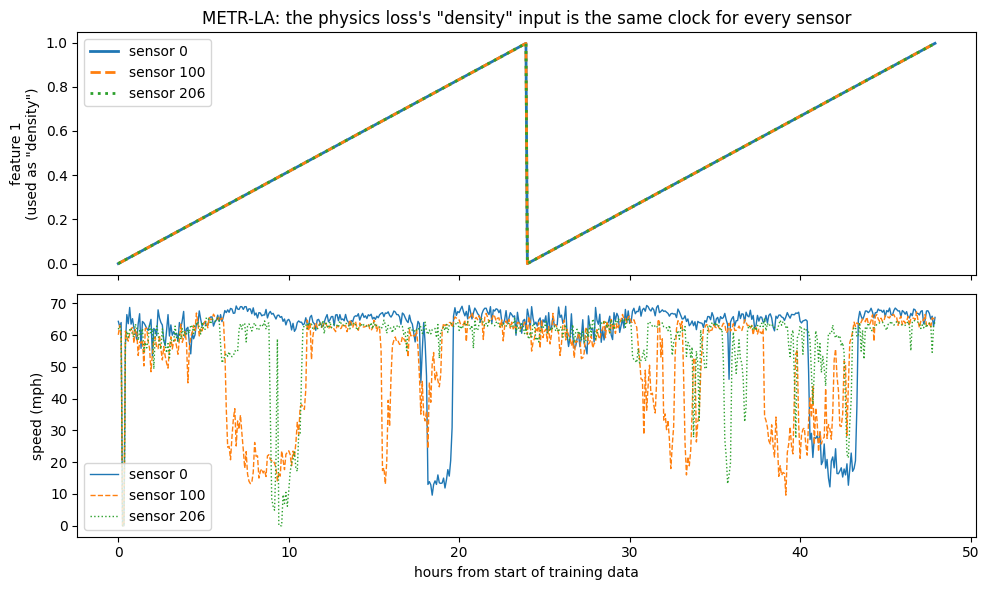

In [ ]:
import numpy as np, matplotlib.pyplot as plt, os
OUT = '/content/drive/MyDrive/CS637/p2/figures'
os.makedirs(OUT, exist_ok=True)

x = np.load('/content/data/METR-LA/train.npz')['x'][:, 0]   # first input step of each sample: (time, 207, 2)
speed, f1 = x[..., 0], x[..., 1]
T = len(f1)

# Checks
same_all_sensors = np.allclose(f1, f1[:, :1])
phase = int(round(f1[0, 0] * 288))
clock = ((np.arange(T) + phase) % 288) / 288                 # 288 five-minute steps per day
is_clock = np.allclose(f1[:, 0], clock, atol=1e-6)
corr = [np.corrcoef(speed[:, s], f1[:, s])[0, 1] for s in range(207)]
lines = [
    f'METR-LA train, feature 1 (what the physics loss uses as "density"):',
    f'  range {f1.min():.3f} .. {f1.max():.3f}',
    f'  identical across all 207 sensors at every time step: {same_all_sensors}',
    f'  equals (minute of day)/1440, i.e. ((t + {phase}) mod 288)/288: {is_clock}',
    f'  correlation speed vs feature 1, median over sensors: {np.median(corr):.3f}',
]
print('\n'.join(lines))
open(f'{OUT}/metrla_feature1_checks.txt', 'w').write('\n'.join(lines) + '\n')

# Figure: (a) feature 1 for three sensors over two days; (b) speed over the same window
days = slice(0, 2 * 288)
hours = np.arange(2 * 288) / 12
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for s, st in zip([0, 100, 206], ['-', '--', ':']):
    ax[0].plot(hours, f1[days, s], st, lw=2, label=f'sensor {s}')
    ax[1].plot(hours, speed[days, s], st, lw=1, label=f'sensor {s}')
ax[0].set_ylabel('feature 1\n(used as "density")')
ax[0].set_title('METR-LA: the physics loss\'s "density" input is the same clock for every sensor')
ax[0].legend(loc='upper left')
ax[1].set_ylabel('speed (mph)')
ax[1].set_xlabel('hours from start of training data')
ax[1].legend(loc='lower left')
fig.tight_layout()
fig.savefig(f'{OUT}/metrla_feature1_is_time_of_day.png', dpi=150)
plt.show()
del x

In [ ]:
!rm -rf /content/authors
!git clone -q --depth 1 --filter=blob:none --sparse https://github.com/tianshubao1/uq4phy_traffic_network /content/authors
!cd /content/authors && git sparse-checkout set gpde_quantile_model gpde_quantile_phy_model && ls

remote: Enumerating objects: 2, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 2 (delta 0), reused 1 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (2/2), 2.72 KiB | 2.72 MiB/s, done.
remote: Enumerating objects: 29, done.
remote: Counting objects: 100% (29/29), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 29 (delta 8), reused 17 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (29/29), 1.84 MiB | 4.01 MiB/s, done.
Resolving deltas: 100% (8/8), done.
Updating files: 100% (60/60), done.
gpde_quantile_model  gpde_quantile_phy_model  LICENSE  README.md


In [ ]:
P2  = '/content/drive/MyDrive/CS637/p2'
SRC = '/content/authors'
for name, src in [('metrla_gpde_quantile', 'gpde_quantile_model'),
                  ('metrla_gpde_quantile_phy', 'gpde_quantile_phy_model')]:
    run = f'{P2}/runs/{name}'
    !cp -r --update=none $SRC/$src $run
    !sed -i 's#dataset_dir: .*#dataset_dir: /content/data/METR-LA#' $run/data/model/dcrnn_la.yaml
    !sed -i 's/yaml.load(f)/yaml.safe_load(f)/' $run/dcrnn_train_pytorch.py
    print('=====', name)
    !grep -n "dataset_dir\|input_dim\|reg\|epochs:\|batch_size\|patience" $run/data/model/dcrnn_la.yaml
    !ls $run/data/sensor_graph
!sed -n '/def underwood_loss/,/return loss.mean()/p' $P2/runs/metrla_gpde_quantile_phy/model/pytorch/loss.py

===== metrla_gpde_quantile
5:  batch_size: 128
6:  dataset_dir: /content/data/METR-LA
7:  test_batch_size: 128
8:  val_batch_size: 128
15:  input_dim: 2
29:  epochs: 50
37:  patience: 50
39:  test_every_n_epochs: 5
adj_mx_1.pkl	  distances_la_2012_1.csv  graph_sensor_locations_1.csv
adj_mx_bay_1.pkl  distances_la_2012.csv    graph_sensor_locations.csv
adj_mx_bay.pkl	  graph_sensor_ids_1.txt   LA_matrix.npy
adj_mx.pkl	  graph_sensor_ids.txt
===== metrla_gpde_quantile_phy
5:  batch_size: 128
6:  dataset_dir: /content/data/METR-LA
7:  test_batch_size: 128
8:  val_batch_size: 128
15:  input_dim: 2
24:  reg: 0.0005
31:  epochs: 50
39:  patience: 50
41:  test_every_n_epochs: 5
adj_mx_1.pkl		 distances_la_2012.csv	       LA_matrix.npy
adj_mx_bay_1.pkl	 graph_sensor_ids_1.txt        METR_LA_rho_max.npy
adj_mx_bay.pkl		 graph_sensor_ids.txt	       METR_LA_v_f.npy
adj_mx.pkl		 graph_sensor_locations_1.csv
distances_la_2012_1.csv  graph_sensor_locations.csv
def underwood_loss(y_pred, x_true, y_tr

In [ ]:
import numpy as np
P2 = '/content/drive/MyDrive/CS637/p2'
G  = f'{P2}/runs/metrla_gpde_quantile_phy/data/sensor_graph'
vf_raw, rm_raw = np.load(f'{G}/METR_LA_v_f.npy'), np.load(f'{G}/METR_LA_rho_max.npy')
print('shipped shapes', vf_raw.shape, rm_raw.shape)
vf, rm = vf_raw.reshape(-1, 207)[0], rm_raw.reshape(-1, 207)[0]
print('copies only:', np.allclose(vf_raw.reshape(-1,207), vf), np.allclose(rm_raw.reshape(-1,207), rm))
print(f'shipped v_f     {vf.min():.2f} .. {vf.max():.2f} (median {np.median(vf):.2f})')
print(f'shipped rho_max {rm.min():.3f} .. {rm.max():.3f} (median {np.median(rm):.3f})')

x = np.load('/content/data/METR-LA/train.npz')['x'][:, 0]   # (time, 207, [speed, time_of_day])
lin_vf, lin_k, log_vf, log_k = [], [], [], []
for s in range(207):
    v, k = x[:, s, 0], x[:, s, 1]
    ok = v > 0                                   # zeros are missing values
    a, b = np.polyfit(k[ok], v[ok], 1);          lin_vf.append(b);         lin_k.append(b / -a)
    a, b = np.polyfit(k[ok], np.log(v[ok]), 1);  log_vf.append(np.exp(b)); log_k.append(-1 / a)
for tag, fv, fk in [('linear fit vs time of day', lin_vf, lin_k), ('log fit vs time of day   ', log_vf, log_k)]:
    print(f'{tag}: v_f diff {np.abs(np.array(fv)-vf).mean():8.3f}   rho diff {np.abs(np.array(fk)-rm).mean():10.3f}')

# What the METR-LA physics term asks the model to predict over one day, for sensor 0:
tod = np.linspace(0, 1, 5)
print('Underwood speed at 00:00, 06:00, 12:00, 18:00, 24:00 for sensor 0:', np.round(vf[0] * np.exp(-tod / rm[0]), 1))
del x

shipped shapes (12, 128, 207) (12, 128, 207)
copies only: True True
shipped v_f     11.77 .. 44.49 (median 35.03)
shipped rho_max -547.277 .. 926.916 (median -3.627)
linear fit vs time of day: v_f diff   25.023   rho diff     54.513
log fit vs time of day   : v_f diff   23.930   rho diff     70.968
Underwood speed at 00:00, 06:00, 12:00, 18:00, 24:00 for sensor 0: [39.1 37.6 36.2 34.8 33.5]


In [ ]:
import numpy as np
P2 = '/content/drive/MyDrive/CS637/p2'
G  = f'{P2}/runs/metrla_gpde_quantile_phy/data/sensor_graph'
vf = np.load(f'{G}/METR_LA_v_f.npy').reshape(-1, 207)[0]
rm = np.load(f'{G}/METR_LA_rho_max.npy').reshape(-1, 207)[0]
x = np.load('/content/data/METR-LA/train.npz')['x'][:, 0]
v, tod = x[..., 0], x[..., 1]
law = vf * np.exp(-tod / rm)                       # what the physics term targets, per time step and sensor
ok = v > 0
gap = np.array([(v[ok[:, s], s] - law[ok[:, s], s]).mean() for s in range(207)])
lines = [
    'METR-LA shipped "Underwood" parameters (gpde_quantile_phy_model, reg 0.0005):',
    f'  sensors with negative k_m (speed rises with "density"): {(rm < 0).sum()} of 207',
    f'  v_f range {vf.min():.1f} .. {vf.max():.1f} mph (median {np.median(vf):.1f}); mean observed speed {v[ok].mean():.1f} mph',
    f'  observed speed minus physics target, median over sensors: {np.median(gap):.1f} mph',
    f'  sensors where the physics target is below the observed mean: {(gap > 0).sum()} of 207',
]
print('\n'.join(lines))
open(f'{P2}/figures/metrla_physics_params_checks.txt', 'w').write('\n'.join(lines) + '\n')
del x

METR-LA shipped "Underwood" parameters (gpde_quantile_phy_model, reg 0.0005):
  sensors with negative k_m (speed rises with "density"): 147 of 207
  v_f range 11.8 .. 44.5 mph (median 35.0); mean observed speed 58.6 mph
  observed speed minus physics target, median over sensors: 20.3 mph
  sensors where the physics target is below the observed mean: 207 of 207


In [ ]:
!ps aux | grep dcrnn_train | grep -v grep
!tail -n 2 /content/drive/MyDrive/CS637/p2/logs/pemsd8_underwood_ours_seed0.log

root       11408 99.0 29.0 15331600 3857356 ?    Rl   08:35  30:11 python3 dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml
2026-10-21 09:05:54,519 - INFO - Epoch [29/50] (2940) val_mae:1.6417, val_mis: 31.4299, val_width: 3.2934, val_mse: 13.3102, val_rmse: 3.6483 , 
2026-10-21 09:06:01,211 - INFO - Epoch [29/50] (2940) test_mae:1.6472,test_mis: 31.2567, test_width: 3.3161, test_mse: 13.4467, test_rmse: 3.6670 , 


In [ ]:
!ps aux | grep dcrnn_train | grep -v grep
!tail -n 2 /content/drive/MyDrive/CS637/p2/logs/pemsd8_underwood_ours_seed0.log

2026-10-21 09:25:48,980 - INFO - Epoch [49/50] (4900) val_mae:1.5874, val_mis: 31.9429, val_width: 2.8985, val_mse: 12.8041, val_rmse: 3.5783 , 
2026-10-21 09:25:55,876 - INFO - Epoch [49/50] (4900) test_mae:1.5835,test_mis: 31.5456, test_width: 2.9260, test_mse: 12.8718, test_rmse: 3.5877 , 


In [ ]:
ROOT = '/content/drive/MyDrive/CS637'
P2   = f'{ROOT}/p2'
!grep "saving to" $P2/logs/pemsd8_underwood_ours_seed0.log | tail -2
!grep "Epoch \[" $P2/logs/pemsd8_underwood_ours_seed0.log | grep test_mae | tail -3
print('===== authors\' log for the same model (gpde_quantile_phy_model_PEMSD8):')
!ls $ROOT/uq4phy_traffic_network/gpde_quantile_phy_model_PEMSD8/data/model/
!grep -h "saving to\|test_mae" $ROOT/uq4phy_traffic_network/gpde_quantile_phy_model_PEMSD8/data/model/dcrnn_*/info.log | tail -6
!ls $ROOT/p1

2026-10-21 09:04:00,946 - INFO - Val loss decrease from 1.5732 to 1.5541, saving to models/epo27.tar
2026-10-21 09:07:02,397 - INFO - Val loss decrease from 1.5541 to 1.5380, saving to models/epo30.tar
2026-10-21 09:23:56,374 - INFO - Epoch [47/50] (4704) test_mae:1.5457,test_mis: 28.8224, test_width: 3.3463, test_mse: 12.3370, test_rmse: 3.5124 , 
2026-10-21 09:24:55,431 - INFO - Epoch [48/50] (4802) test_mae:1.5866,test_mis: 29.2883, test_width: 3.3983, test_mse: 12.5523, test_rmse: 3.5429 , 
2026-10-21 09:25:55,876 - INFO - Epoch [49/50] (4900) test_mae:1.5835,test_mis: 31.5456, test_width: 2.9260, test_mse: 12.8718, test_rmse: 3.5877 , 
===== authors' log for the same model (gpde_quantile_phy_model_PEMSD8):
dcrnn_la.yaml  pretrained
grep: /content/drive/MyDrive/CS637/uq4phy_traffic_network/gpde_quantile_phy_model_PEMSD8/data/model/dcrnn_*/info.log: No such file or directory
logs  results  scripts


In [ ]:
%cd $P2/runs/metrla_gpde_quantile
!nohup python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > $P2/logs/metrla_gpde_quantile_seed0.log 2>&1 &

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/metrla_gpde_quantile


In [ ]:
!grep "Epoch \[" $P2/logs/metrla_gpde_quantile_seed0.log | grep test_mae
!grep "Start training\|epoch complete" $P2/logs/metrla_gpde_quantile_seed0.log | head -4

2026-10-21 09:43:44,115 - INFO - Start training ...
2026-10-21 09:45:57,913 - INFO - epoch complete


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!pkill -f dcrnn_train_pytorch; sleep 3; ps aux | grep dcrnn_train | grep -v grep
for name in ['metrla_gpde_quantile', 'metrla_gpde_quantile_phy']:
    run = f'{P2}/runs/{name}'
    !sed -i 's/epochs: 50/epochs: 25/; s/patience: 50/patience: 25/' $run/data/model/dcrnn_la.yaml
    !rm -rf $run/models
    !grep -n "epochs:\|patience" $run/data/model/dcrnn_la.yaml
%cd $P2/runs/metrla_gpde_quantile
!nohup python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > $P2/logs/metrla_gpde_quantile_seed0.log 2>&1 &

^C
29:  epochs: 25
37:  patience: 25
39:  test_every_n_epochs: 5
31:  epochs: 25
39:  patience: 25
41:  test_every_n_epochs: 5
/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/metrla_gpde_quantile


In [ ]:
!free -h
!ps aux | grep dcrnn_train | grep -v grep | awk '{print $6/1e6 " GB"}'


               total        used        free      shared  buff/cache   available
Mem:            12Gi        10Gi       890Mi        20Mi       1.3Gi       1.9Gi
Swap:             0B          0B          0B
7.14274 GB


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!ps aux | grep dcrnn_train | grep -v grep
!grep "epoch complete\|Epoch \[" $P2/logs/metrla_gpde_quantile_seed0.log | tail -3

root       29917 98.8 53.7 19492060 7142676 ?    Sl   09:47  14:23 python3 dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml
2026-10-21 10:01:12,108 - INFO - epoch complete
2026-10-21 10:01:21,560 - INFO - Epoch [4/25] (940) val_mae:3.5416, val_mis: 53.4970, val_width: 11.1020, val_mse: 54.6934, val_rmse: 7.3955 , 
2026-10-21 10:01:40,568 - INFO - Epoch [4/25] (940) test_mae:3.7723,test_mis: 57.7768, test_width: 11.9610, test_mse: 59.0749, test_rmse: 7.6860 , 


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!cp -r --update=none $P2/runs/pemsd8_underwood_ours $P2/runs/pemsd8_greenshields
!rm -rf $P2/runs/pemsd8_greenshields/models $P2/runs/pemsd8_greenshields/data/model/dcrnn_DR_*
!ls $P2/runs/pemsd8_greenshields/data/model
!grep -n "physics_losses" $P2/runs/pemsd8_greenshields/model/pytorch/dcrnn_supervisor.py
!ls $P2/params

dcrnn_la.yaml  pretrained
12:from model.pytorch.physics_losses import underwood_loss
fit_quality.csv		greenshields_v_f.npy  underwood_v_f.npy
greenshields_k_jam.npy	underwood_k_m.npy


In [ ]:
%cd $P2/runs/pemsd8_greenshields
!PHYS_LAW=greenshields PHYS_VF=$P2/params/greenshields_v_f.npy PHYS_K=$P2/params/greenshields_k_jam.npy nohup python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > $P2/logs/pemsd8_greenshields_seed0.log 2>&1 &

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/pemsd8_greenshields


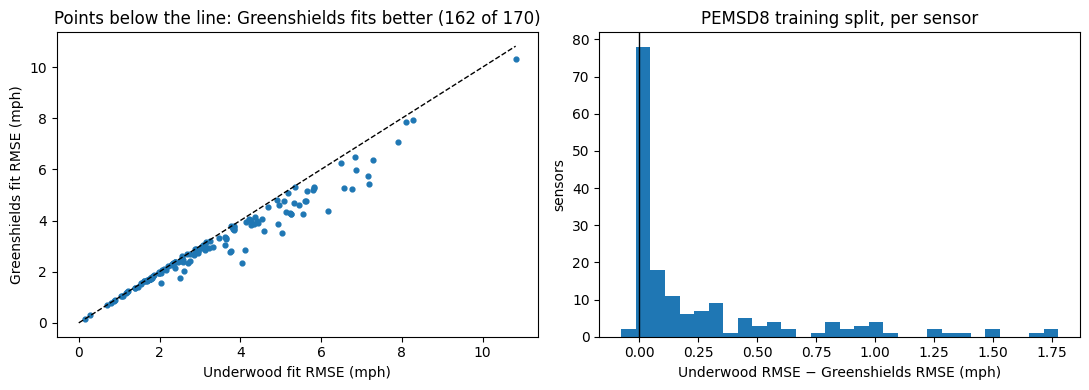

In [ ]:
import pandas as pd, matplotlib.pyplot as plt, numpy as np
q = pd.read_csv(f'{P2}/params/fit_quality.csv')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(q.underwood_rmse, q.greenshields_rmse, s=12)
m = max(q.underwood_rmse.max(), q.greenshields_rmse.max())
ax[0].plot([0, m], [0, m], 'k--', lw=1)
ax[0].set_xlabel('Underwood fit RMSE (mph)'); ax[0].set_ylabel('Greenshields fit RMSE (mph)')
ax[0].set_title(f'Points below the line: Greenshields fits better ({(q.greenshields_rmse < q.underwood_rmse).sum()} of {len(q)})')
ax[1].hist(q.underwood_rmse - q.greenshields_rmse, bins=30)
ax[1].axvline(0, color='k', lw=1)
ax[1].set_xlabel('Underwood RMSE − Greenshields RMSE (mph)'); ax[1].set_ylabel('sensors')
ax[1].set_title('PEMSD8 training split, per sensor')
fig.tight_layout(); fig.savefig(f'{P2}/figures/pemsd8_greenshields_vs_underwood_fit.png', dpi=150); plt.show()

In [ ]:
print((q.greenshields_rmse < q.underwood_rmse).sum(), (q.greenshields_rmse == q.underwood_rmse).sum(), (q.greenshields_rmse > q.underwood_rmse).sum())

NameError: name 'q' is not defined

In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!ps aux | grep dcrnn_train | grep -v grep
!grep "epoch complete\|Epoch \[" $P2/logs/metrla_gpde_quantile_seed0.log | tail -3

2026-10-21 10:01:40,568 - INFO - Epoch [4/25] (940) test_mae:3.7723,test_mis: 57.7768, test_width: 11.9610, test_mse: 59.0749, test_rmse: 7.6860 , 
2026-10-21 10:03:55,062 - INFO - epoch complete
2026-10-21 10:04:07,931 - INFO - Epoch [5/25] (1128) val_mae:3.4779, val_mis: 53.5535, val_width: 10.6904, val_mse: 53.3974, val_rmse: 7.3074 , 


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!ps aux | grep dcrnn_train | grep -v grep
!tail -n 2 $P2/logs/metrla_gpde_quantile_seed0.log
!ls /content/data
!free -h

2026-10-21 10:03:55,063 - INFO - evaluating now!
2026-10-21 10:04:07,931 - INFO - Epoch [5/25] (1128) val_mae:3.4779, val_mis: 53.5535, val_width: 10.6904, val_mse: 53.3974, val_rmse: 7.3074 , 
METR-LA  PEMSD8
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.5Gi        10Gi       6.6Mi       1.2Gi        11Gi
Swap:             0B          0B          0B


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
RUN = f'{P2}/runs/metrla_gpde_quantile'
%cd $RUN
!rm -rf models data/model/dcrnn_DR_*
!grep -n "epochs:\|dataset_dir" data/model/dcrnn_la.yaml
!nohup python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > $P2/logs/metrla_gpde_quantile_seed0.log 2>&1 &

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/metrla_gpde_quantile
6:  dataset_dir: /content/data/METR-LA
29:  epochs: 25
39:  test_every_n_epochs: 5


In [ ]:
  !ps aux | grep dcrnn_train | grep -v grep; tail -n 1 /content/drive/MyDrive/CS637/p2/logs/metrla_gpde_quantile_seed0.log

root       36461 65.1 21.1 12187264 2813840 ?    Rl   10:12   0:12 python3 dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml
2026-10-21 10:12:46,949 - INFO - Log directory: data/model/dcrnn_DR_2_h_12_16-16_lr_0.01_bs_128_1021101246/


In [ ]:
  !ps aux | grep dcrnn_train | grep -v grep; tail -n 1 /content/drive/MyDrive/CS637/p2/logs/metrla_gpde_quantile_seed0.log

root       36461 99.4 56.1 19491940 7455944 ?    Rl   10:12  53:56 python3 dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml
2026-10-21 11:05:13,906 - INFO - Val loss decrease from 3.3181 to 3.2815, saving to models/epo19.tar


In [ ]:
  !ps aux | grep dcrnn_train | grep -v grep; tail -n 1 /content/drive/MyDrive/CS637/p2/logs/metrla_gpde_quantile_seed0.log

2026-10-21 11:18:17,294 - INFO - Epoch [24/25] (4700) test_mae:3.5207,test_mis: 54.8540, test_width: 10.9554, test_mse: 54.8625, test_rmse: 7.4069 , 


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
%cd $P2/runs/metrla_gpde_quantile_phy
!grep -n "epochs:" data/model/dcrnn_la.yaml
!nohup python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > $P2/logs/metrla_gpde_quantile_phy_seed0.log 2>&1 &

/content/drive/.shortcut-targets-by-id/11I4ISvnKevyha05DWHYzxsz9vShaZGv6/CS637/p2/runs/metrla_gpde_quantile_phy
31:  epochs: 25
41:  test_every_n_epochs: 5


In [ ]:
  !ps aux | grep dcrnn_train | grep -v grep; tail -n 1 /content/drive/MyDrive/CS637/p2/logs/metrla_gpde_quantile_seed0.log

root       56813 98.8 56.3 19541600 7488308 ?    Rl   11:30  34:08 python3 dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml
2026-10-21 11:18:17,294 - INFO - Epoch [24/25] (4700) test_mae:3.5207,test_mis: 54.8540, test_width: 10.9554, test_mse: 54.8625, test_rmse: 7.4069 , 


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!ps aux | grep dcrnn_train | grep -v grep
!grep "Epoch \[" $P2/logs/metrla_gpde_quantile_phy_seed0.log | grep test_mae | tail -1
!grep "saving to" $P2/logs/metrla_gpde_quantile_phy_seed0.log | tail -1

root       56813 98.6 56.3 19541600 7488308 ?    Rl   11:30  35:09 python3 dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml
2026-10-21 12:06:19,589 - INFO - Epoch [12/25] (2444) test_mae:3.6158,test_mis: 56.5301, test_width: 10.8357, test_mse: 55.2330, test_rmse: 7.4319 , 
2026-10-21 12:06:19,610 - INFO - Val loss decrease from 3.4205 to 3.4142, saving to models/epo12.tar


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!ps aux | grep dcrnn_train | grep -v grep
!grep "Epoch \[" $P2/logs/metrla_gpde_quantile_phy_seed0.log | grep test_mae | tail -1
!grep "saving to" $P2/logs/metrla_gpde_quantile_phy_seed0.log | tail -1

root       56813 98.7 57.9 19755228 7701936 ?    Rl   11:30  58:57 python3 dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml
2026-10-21 12:28:07,792 - INFO - Epoch [20/25] (3948) test_mae:3.4505,test_mis: 50.6231, test_width: 11.0721, test_mse: 49.1934, test_rmse: 7.0138 , 
2026-10-21 12:28:07,808 - INFO - Val loss decrease from 3.3137 to 3.2638, saving to models/epo20.tar


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!ps aux | grep dcrnn_train | grep -v grep
!grep "Epoch \[" $P2/logs/metrla_gpde_quantile_phy_seed0.log | grep test_mae | tail -1
!grep "saving to" $P2/logs/metrla_gpde_quantile_phy_seed0.log | tail -1

2026-10-21 12:38:44,042 - INFO - Epoch [24/25] (4700) test_mae:3.5093,test_mis: 52.7664, test_width: 10.7491, test_mse: 50.6434, test_rmse: 7.1164 , 
2026-10-21 12:30:48,228 - INFO - Val loss decrease from 3.2638 to 3.2523, saving to models/epo21.tar


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
for f in ['metrla_gpde_quantile', 'metrla_gpde_quantile_phy']:
    print('=====', f)
    !grep "saving to" $P2/logs/{f}_seed0.log | tail -1
    !grep "test_mae" $P2/logs/{f}_seed0.log | tail -1
!ls $P2/runs/metrla_gpde_quantile/models $P2/runs/metrla_gpde_quantile_phy/models

===== metrla_gpde_quantile
2026-10-21 11:15:41,804 - INFO - Val loss decrease from 3.2568 to 3.2519, saving to models/epo23.tar
2026-10-21 11:18:17,294 - INFO - Epoch [24/25] (4700) test_mae:3.5207,test_mis: 54.8540, test_width: 10.9554, test_mse: 54.8625, test_rmse: 7.4069 , 
===== metrla_gpde_quantile_phy
2026-10-21 12:30:48,228 - INFO - Val loss decrease from 3.2638 to 3.2523, saving to models/epo21.tar
2026-10-21 12:38:44,042 - INFO - Epoch [24/25] (4700) test_mae:3.5093,test_mis: 52.7664, test_width: 10.7491, test_mse: 50.6434, test_rmse: 7.1164 , 
/content/drive/MyDrive/CS637/p2/runs/metrla_gpde_quantile/models:
epo0.tar   epo14.tar  epo1.tar	 epo23.tar  epo4.tar  epo7.tar
epo11.tar  epo15.tar  epo20.tar  epo2.tar   epo5.tar
epo12.tar  epo19.tar  epo21.tar  epo3.tar   epo6.tar

/content/drive/MyDrive/CS637/p2/runs/metrla_gpde_quantile_phy/models:
epo0.tar   epo13.tar  epo16.tar  epo21.tar  epo7.tar
epo11.tar  epo14.tar  epo1.tar	 epo3.tar   epo8.tar
epo12.tar  epo15.tar  epo20.ta

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, requests
for name, aid in {'PEMSD8': 28347662, 'METR-LA': 28347830}.items():
    d = f'/content/data/{name}'; os.makedirs(d, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{aid}').json()['files']:
        p = f"{d}/{f['name']}"
        if os.path.exists(p) and os.path.getsize(p) == f['size']: continue
        r = requests.get(f['download_url'], stream=True, timeout=120, headers={'User-Agent': 'Mozilla/5.0'})
        with open(p, 'wb') as out:
            for c in r.iter_content(1 << 20): out.write(c)
!ls -lh /content/data/PEMSD8 /content/data/METR-LA

Mounted at /content/drive
/content/data/METR-LA:
total 357M
-rw-r--r-- 1 root root  70M Oct 22 07:18 test.npz
-rw-r--r-- 1 root root 252M Oct 22 07:19 train.npz
-rw-r--r-- 1 root root  36M Oct 22 07:19 val.npz

/content/data/PEMSD8:
total 901M
-rw-r--r-- 1 root root  70M Oct 22 07:18  pems8ndy.npy
-rw-r--r-- 1 root root 3.0K Oct 22 07:18 'PEMSD8 data processing.py'
-rw-r--r-- 1 root root 166M Oct 22 07:18  test.npz
-rw-r--r-- 1 root root 583M Oct 22 07:18  train.npz
-rw-r--r-- 1 root root  83M Oct 22 07:18  val.npz


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
RUN = f'{P2}/runs/pemsd8_greenshields'
!cp -r --update=none $P2/runs/pemsd8_underwood_ours $RUN
!rm -rf $RUN/models $RUN/data/model/dcrnn_DR_*
!grep -n "physics_losses" $RUN/model/pytorch/dcrnn_supervisor.py
!grep -n "dataset_dir\|reg:\|epochs:" $RUN/data/model/dcrnn_la.yaml
!ls $P2/params
%cd $RUN
!PHYS_LAW=greenshields PHYS_VF=$P2/params/greenshields_v_f.npy PHYS_K=$P2/params/greenshields_k_jam.npy nohup python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > $P2/logs/pemsd8_greenshields_seed0.log 2>&1 &

cp: cannot create directory '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8_underwood_ours/data/model': No such file or directory
cp: cannot create directory '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8_underwood_ours/data/sensor_graph': No such file or directory
cp: cannot create directory '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8_underwood_ours/lib': No such file or directory
cp: cannot create regular file '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8_underwood_ours/run_demo_pytorch.py': No such file or directory
cp: cannot create directory '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8_underwood_ours/gpde_quantile_phy_model_PEMSD8': No such file or directory
cp: cannot create regular file '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8_underwood_ours/dcrnn_train_pytorch.py': No such file or directory
cp: cannot create directory '/content/drive/MyDrive/CS637/p2/runs/pemsd

In [ ]:
ROOT = '/content/drive/MyDrive/CS637'
!ls $ROOT/p1/scripts
!for f in $ROOT/p1/scripts/*.py; do echo "===== $f"; head -n 40 "$f"; done
!sed -n '/def evaluate/,/return/p; /def load_model/,/return\|logger/p' $P2/runs/pemsd8_underwood_ours/model/pytorch/dcrnn_supervisor.py

check_sparse.py     horizon_metrics.py	__pycache__
eval_checkpoint.py  process_pems.py
===== {'id': 52136591, 'name': 'val.npz', 'size': 37406550, 'is_link_only': False, 'download_url': 'https://ndownloader.figshare.com/files/52136591', 'supplied_md5': 'ab184a3b5353eb0d8471852814170ce8', 'computed_md5': 'ab184a3b5353eb0d8471852814170ce8', 'mimetype': 'application/zip'}
head: cannot open '{'\''id'\'': 52136591, '\''name'\'': '\''val.npz'\'', '\''size'\'': 37406550, '\''is_link_only'\'': False, '\''download_url'\'': '\''https://ndownloader.figshare.com/files/52136591'\'', '\''supplied_md5'\'': '\''ab184a3b5353eb0d8471852814170ce8'\'', '\''computed_md5'\'': '\''ab184a3b5353eb0d8471852814170ce8'\'', '\''mimetype'\'': '\''application/zip'\''}' for reading: No such file or directory
===== {'id': 52136591, 'name': 'val.npz', 'size': 37406550, 'is_link_only': False, 'download_url': 'https://ndownloader.figshare.com/files/52136591', 'supplied_md5': 'ab184a3b5353eb0d8471852814170ce8', 'computed_

In [ ]:
!ps aux | grep dcrnn_train | grep -v grep; tail -n 2 /content/drive/MyDrive/CS637/p2/logs/pemsd8_greenshields_seed0.log

root        1197 93.6 29.0 15300272 3866264 ?    Sl   07:19   2:47 python3 dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml
2026-10-22 07:21:56,131 - INFO - Saved model at 1
2026-10-22 07:21:56,132 - INFO - Val loss decrease from 3.7647 to 3.6638, saving to models/epo1.tar


In [ ]:
ROOT = '/content/drive/MyDrive/CS637'
for name in ['eval_checkpoint.py', 'horizon_metrics.py']:
    print(f'===================== {name}')
    print(open(f'{ROOT}/p1/scripts/{name}').read())

===================== eval_checkpoint.py
"""Evaluate one of the authors' shipped checkpoints and save val + test predictions.

Run from INSIDE a variant folder of the authors' repo, e.g.
    cd .../uq4phy_traffic_network/gpde_quantile_phy_model_PEMSD4
    python /path/eval_checkpoint.py --data_dir /content/pemsd4 --out /path/model.npz
The authors' code is not modified: we load their pretrained config with yaml.safe_load
(their run_demo uses yaml.load(f), which fails on PyYAML 6) and let torch.load read
their full checkpoint dict (PyTorch >= 2.6 defaults to weights_only=True).
"""
import argparse, glob, json, os, sys, time
import numpy as np, torch, yaml

_torch_load = torch.load
def _load(*a, **k):
    k.setdefault('weights_only', False)
    return _torch_load(*a, **k)
torch.load = _load

sys.path.insert(0, os.getcwd())
from lib.utils import load_graph_data                      # noqa: E402  (authors' code)
from model.pytorch.dcrnn_supervisor import DCRNNSupervisor  # noqa: E402

p = a

In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!python $P2/implementation/eval_run.py --run $P2/runs/pemsd8_underwood_ours --epoch 30 \
    --data_dir /content/data/PEMSD8 --label pemsd8_underwood_ours --csv $P2/results/horizon_metrics.csv

shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
python3: can't open file '/content/drive/MyDrive/CS637/p2/implementation/eval_run.py': [Errno 2] No such file or directory


In [ ]:
!ls -la /content/drive/MyDrive/CS637/p2/implementation/
!find /content/drive/MyDrive/CS637/p2 -maxdepth 3 -name "eval_run*"

total 25
drwx------ 4 root root 4096 Oct 21 08:31 .
drwx------ 8 root root 4096 Oct 21 07:50 ..
-rw------- 1 root root 3490 Oct 21 08:30 fit_params.py
-rw------- 1 root root 5600 Oct 21 08:30 physics_losses.py
drwx------ 2 root root 4096 Oct 21 08:33 __pycache__
drwx------ 2 root root 4096 Oct 21 08:31 tests


In [ ]:
  from google.colab import drive
  drive.flush_and_unmount()
  drive.mount('/content/drive', force_remount=True)
  !ls /content/drive/MyDrive/CS637/p2/implementation/

Mounted at /content/drive
shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
fit_params.py  physics_losses.py  __pycache__  tests


In [ ]:
%cd /content
!ps aux | grep dcrnn_train | grep -v grep
!tail -n 3 /content/drive/MyDrive/CS637/p2/logs/pemsd8_greenshields_seed0.log

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_261/164588774.py", line 1, in <cell line: 0>
    get_ipython().run_line_magic('cd', '/content')
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 2418, in run_line_magic
    result = fn(*args, **kwargs)
  File "<decorator-gen-85>", line 2, in cd
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/magic.py", line 187, in <lambda>
    call = lambda f, *a, **k: f(*a, **k)
                              ~^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/magics/osm.py", line 342, in cd
    oldcwd = os.getcwd()
OSError: [Errno 107] Transport endpoint is not connected

During handling of the above exception, a

In [ ]:
import os; os.chdir('/content')
from google.colab import drive
drive.mount('/content/drive')
!ls /content/data
!ps aux | grep dcrnn_train | grep -v grep
!tail -n 3 /content/drive/MyDrive/CS637/p2/logs/pemsd8_greenshields_seed0.log

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
METR-LA  PEMSD8
tail: cannot open '/content/drive/MyDrive/CS637/p2/logs/pemsd8_greenshields_seed0.log' for reading: No such file or directory


In [ ]:
import os
P2 = '/content/drive/MyDrive/CS637/p2'
RUN = f'{P2}/runs/pemsd8_greenshields'
print('p2 exists:', os.path.isdir(P2), '| runs:', os.listdir(f'{P2}/runs'), '| params:', os.listdir(f'{P2}/params'))

!cp -r --update=none $P2/runs/pemsd8_underwood_ours $RUN
!rm -rf $RUN/models $RUN/data/model/dcrnn_DR_*
!mkdir -p $P2/logs
!grep -n "physics_losses" $RUN/model/pytorch/dcrnn_supervisor.py
!grep -n "dataset_dir\|reg:\|epochs:" $RUN/data/model/dcrnn_la.yaml

os.chdir(RUN)
!PHYS_LAW=greenshields PHYS_VF=$P2/params/greenshields_v_f.npy PHYS_K=$P2/params/greenshields_k_jam.npy nohup python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > $P2/logs/pemsd8_greenshields_seed0.log 2>&1 &
os.chdir('/content')

p2 exists: True | runs: ['pemsd8_underwood_ours', 'metrla_gpde_quantile', 'metrla_gpde_quantile_phy', 'pemsd8_greenshields'] | params: ['underwood_v_f.npy', 'underwood_k_m.npy', 'greenshields_v_f.npy', 'greenshields_k_jam.npy', 'fit_quality.csv']
cp: cannot create regular file '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8_underwood_ours/data/sensor_graph/graph_sensor_ids.txt': No such file or directory
cp: cannot create regular file '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8_underwood_ours/data/sensor_graph/graph_sensor_locations.csv': No such file or directory
cp: cannot create directory '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8_underwood_ours/lib': No such file or directory
cp: cannot create regular file '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8_underwood_ours/run_demo_pytorch.py': No such file or directory
cp: cannot create directory '/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/pemsd8

In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!rm -rf $P2/runs/pemsd8_greenshields/pemsd8_underwood_ours
!ls $P2/runs/pemsd8_greenshields
!ps aux | grep dcrnn_train | grep -v grep; tail -n 3 $P2/logs/pemsd8_greenshields_seed0.log

data				lib		     scripts
dcrnn_train_pytorch.py		model
gpde_quantile_phy_model_PEMSD8	run_demo_pytorch.py
root        6048 98.1 28.8 15264724 3832400 ?    Rl   07:37   0:38 python3 dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml
  decoder_input = decoder_output.T[1].T
epoch_num =  0
2026-10-22 07:38:07,327 - INFO - Total trainable parameters 24931


In [ ]:
from google.colab import files
import shutil
up = files.upload()                      # choose eval_run.py
shutil.move(list(up)[0], '/content/drive/MyDrive/CS637/p2/implementation/eval_run.py')

IndexError: list index out of range

In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!ls $P2/implementation
!python $P2/implementation/eval_run.py --run $P2/runs/pemsd8_underwood_ours --epoch 30 \
    --data_dir /content/data/PEMSD8 --label pemsd8_underwood_ours --csv $P2/results/horizon_metrics.csv

fit_params.py  physics_losses.py  __pycache__  tests
python3: can't open file '/content/drive/MyDrive/CS637/p2/implementation/eval_run.py': [Errno 2] No such file or directory


In [ ]:
import os; os.chdir('/content')
from google.colab import files
files.upload()
!ls -la /content/eval_run.py

Saving eval_run.py to eval_run.py
-rw-r--r-- 1 root root 5246 Oct 22 08:16 /content/eval_run.py


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
!python /content/eval_run.py --run $P2/runs/pemsd8_underwood_ours --epoch 30 \
    --data_dir /content/data/PEMSD8 --label pemsd8_underwood_ours --csv $P2/results/horizon_metrics.csv

python3: can't open file '/content/eval_run.py': [Errno 2] No such file or directory


In [ ]:
import os, subprocess, re, glob
P2 = '/content/drive/MyDrive/CS637/p2'   # adjust if your shortcut lands elsewhere
os.chdir('/content')

print(subprocess.run('ps aux | grep dcrnn_train | grep -v grep', shell=True, capture_output=True, text=True).stdout or 'NO TRAINING PROCESS')
print(subprocess.run('nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv', shell=True, capture_output=True, text=True).stdout)

log = f'{P2}/logs/pemsd8_greenshields_seed0.log'
lines = open(log).read().splitlines()
print('\n'.join(lines[-15:]))
saves = [l for l in lines if 'saving to' in l]
print('last save:', saves[-1] if saves else 'none yet')
print(sorted(glob.glob(f'{P2}/runs/pemsd8_greenshields/models/*.tar')))
print('data present:', os.path.isdir('/content/data/PEMSD8'))

NO TRAINING PROCESS
utilization.gpu [%], memory.used [MiB]
0 %, 0 MiB



FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/CS637/p2/logs/pemsd8_greenshields_seed0.log'

In [ ]:
import os, glob, shutil
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')

print(os.listdir('/content/drive/MyDrive'))
hits = glob.glob('/content/drive/MyDrive/**/p2/logs', recursive=True)
print(hits)

Mounted at /content/drive
['Colab Notebooks', 'dcrnn_supervisor.cpython-313.pyc', 'CS637']
['/content/drive/MyDrive/CS637/p2/logs']


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'   # fix if Cell 1 showed otherwise
print(sorted(os.listdir(f'{P2}/logs')))
print(sorted(glob.glob(f'{P2}/runs/pemsd8_greenshields/models/*.tar')))
gl = f'{P2}/logs/pemsd8_greenshields_seed0.log'
if os.path.exists(gl):
    print('\n'.join(open(gl).read().splitlines()[-10:]))

['metrla_gpde_quantile_phy_seed0.log', 'metrla_gpde_quantile_seed0.log', 'pemsd8_greenshields_seed0 (1).log', 'pemsd8_greenshields_seed0.log', 'pemsd8_underwood_ours_seed0.log', 'timing_pemsd8.log']
['/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/models/epo45.tar']
epoch_num =  48
2026-10-22 08:27:52,825 - INFO - epoch complete
2026-10-22 08:27:52,826 - INFO - evaluating now!
2026-10-22 08:27:56,203 - INFO - Epoch [48/50] (4802) val_mae:1.9472, val_mis: 38.9209, val_width: 3.2386, val_mse: 14.1602, val_rmse: 3.7630 , 
2026-10-22 08:28:02,983 - INFO - Epoch [48/50] (4802) test_mae:1.9381,test_mis: 38.1775, test_width: 3.2615, test_mse: 14.0872, test_rmse: 3.7533 , 
epoch_num =  49
2026-10-22 08:28:53,406 - INFO - epoch complete
2026-10-22 08:28:53,407 - INFO - evaluating now!
2026-10-22 08:28:56,801 - INFO - Epoch [49/50] (4900) val_mae:1.5592, val_mis: 31.6317, val_width: 2.8962, val_mse: 12.4651, val_rmse: 3.5306 , 
2026-10-22 08:29:03,648 - INFO - Epoch [49/50] (4900) test

In [ ]:
gl = f'{P2}/logs/pemsd8_greenshields_seed0.log'
L = open(gl).read().splitlines()
print([l for l in L if 'saving to' in l][-3:])
print([l for l in L if 'Epoch [45/50]' in l])
dup = f'{P2}/logs/pemsd8_greenshields_seed0 (1).log'
print(os.path.getsize(gl), os.path.getsize(dup))
print('\n'.join(open(dup).read().splitlines()[-3:]))

['2026-10-22 08:07:26,917 - INFO - Val loss decrease from 1.5679 to 1.5448, saving to models/epo28.tar', '2026-10-22 08:16:34,338 - INFO - Val loss decrease from 1.5448 to 1.5320, saving to models/epo37.tar', '2026-10-22 08:25:00,788 - INFO - Val loss decrease from 1.5320 to 1.5220, saving to models/epo45.tar']
['2026-10-22 08:24:53,951 - INFO - Epoch [45/50] (4508) val_mae:1.5220, val_mis: 28.7365, val_width: 3.2077, val_mse: 12.4380, val_rmse: 3.5268 , ', '2026-10-22 08:25:00,773 - INFO - Epoch [45/50] (4508) test_mae:1.5238,test_mis: 28.4600, test_width: 3.2235, test_mse: 12.4203, test_rmse: 3.5242 , ']
24509 7572
2026-10-22 07:31:06,896 - INFO - Epoch [10/50] (1078) test_mae:1.8783,test_mis: 37.2750, test_width: 3.3985, test_mse: 15.4458, test_rmse: 3.9301 , 
2026-10-22 07:31:06,911 - INFO - Saved model at 10
2026-10-22 07:31:06,912 - INFO - Val loss decrease from 1.9684 to 1.8887, saving to models/epo10.tar


In [ ]:
shutil.copy(f'{P2}/implementation/eval_run.py', '/content/eval_run.py')
CSV = f'{P2}/results/horizon_metrics.csv'
!python /content/eval_run.py --run {P2}/runs/pemsd8_underwood_ours --epoch 30 \
   --data_dir /content/data/PEMSD8 --label pemsd8_underwood_ours --csv {CSV}

I0000 00:00:1792659462.538983    4945 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792659464.753916    4945 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 08:57:49,605 - INFO - Log directory: /content/p2_eval_logs/pemsd8_underwood_ours
Traceback (most recent call last):
  File "/content/eval_run.py", line 68, in <module>
    sup = DCRNNSupervisor(adj_mx=adj, **cfg)
  File "/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours/model/pytorch/dcrnn_supervisor.py", line 39, in __init__
    self._data = utils.load_dataset(**self._data_kwargs)
                 ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours/lib/utils.py", line 181, in load_dataset
   

In [ ]:
print(os.listdir('/content/data/PEMSD8'))   # expect train.npz, val.npz, test.npz

FileNotFoundError: [Errno 2] No such file or directory: '/content/data/PEMSD8'

In [ ]:
import os, requests, zipfile

def get_figshare(article_id, name):
    out = f'/content/data/{name}'
    os.makedirs(out, exist_ok=True)
    files = requests.get(f'https://api.figshare.com/v2/articles/{article_id}/files').json()
    for f in files:
        dst = os.path.join(out, f['name'])
        print('downloading', f['name'], round(f['size']/1e6), 'MB')
        with requests.get(f['download_url'], stream=True) as r:
            r.raise_for_status()
            with open(dst, 'wb') as fh:
                for chunk in r.iter_content(1 << 20):
                    fh.write(chunk)
        if dst.endswith('.zip'):
            zipfile.ZipFile(dst).extractall(out); os.remove(dst)
    print(name, sorted(os.listdir(out)))

get_figshare(28347662, 'PEMSD8')

downloading train.npz 611 MB
downloading PEMSD8 data processing.py 0 MB
downloading pems8ndy.npy 73 MB
downloading val.npz 86 MB
downloading test.npz 174 MB
PEMSD8 ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']


In [ ]:
!python /content/eval_run.py --run {P2}/runs/pemsd8_underwood_ours --epoch 30 \
   --data_dir /content/data/PEMSD8 --label pemsd8_underwood_ours --csv {CSV}

I0000 00:00:1792659640.853373    5721 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792659643.116676    5721 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 09:00:45,051 - INFO - Log directory: /content/p2_eval_logs/pemsd8_underwood_ours
/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp

In [ ]:
import re
src = open(f'{P2}/runs/pemsd8_underwood_ours/model/pytorch/dcrnn_supervisor.py').read()
i = src.find('def evaluate')
j = src.find('\n    def ', i + 10)
body = src[i:j]
print('\n'.join(l for l in body.splitlines() if 'return' in l or 'def evaluate' in l))
!sed -n '65,90p' /content/eval_run.py

def evaluate(self, dataset='val', batches_seen=0):
        :return: mean L1Loss
            return loss_mis,loss_width,loss_mse,loss_rmse,loss_mae#,{'prediction': y_preds_scaled, 'truth': y_truths_scaled}

_, _, adj = load_graph_data(cfg['data']['graph_pkl_filename'])
t0 = time.time()
sup = DCRNNSupervisor(adj_mx=adj, **cfg)

rows, saved = [], {}
meta = dict(label=a.label, run=run, epoch=a.epoch, law=a.law, reg_lambda=cfg['model'].get('reg'))
for split in ['val', 'test']:
    mis, width, mse, rmse, mae, out = sup.evaluate(split)
    n = len(np.load(os.path.join(a.data_dir, split + '.npz'))['y'])
    pred = np.stack(out['prediction']).astype(np.float32)[:, :n]   # drop padding copies of the last sample
    truth = np.stack(out['truth']).astype(np.float32)[:, :n]
    meta[f'{split}_authors_metrics'] = dict(mae=float(mae), mis=float(mis), width=float(width),
                                            mse=float(mse), rmse=float(rmse))
    print(f'{a.label} {split}: authors-style all-horiz

In [ ]:
p = '/content/eval_run.py'
s = open(p).read()
anchor = "sup = DCRNNSupervisor(adj_mx=adj, **cfg)\n"
patch = anchor + '''
# Some variants comment out the predictions in evaluate()'s return; re-enable at runtime (authors' files untouched).
import inspect, textwrap, sys as _sys
_S = _sys.modules[DCRNNSupervisor.__module__]
_src = textwrap.dedent(inspect.getsource(DCRNNSupervisor.evaluate))
if "loss_mae#,{" in _src:
    assert _src.count("y_preds_scaled") >= 2, "predictions are not built in evaluate(); cannot re-enable"
    _ns = {}
    exec(_src.replace("loss_mae#,{", "loss_mae,{"), _S.__dict__, _ns)
    DCRNNSupervisor.evaluate = _ns["evaluate"]
    print("evaluate(): prediction output re-enabled")
'''
assert anchor in s and 'prediction output re-enabled' not in s
open(p, 'w').write(s.replace(anchor, patch))
shutil.copy(p, f'{P2}/implementation/eval_run.py')

'/content/drive/MyDrive/CS637/p2/implementation/eval_run.py'

In [ ]:
!python /content/eval_run.py --run {P2}/runs/pemsd8_underwood_ours --epoch 30 \
   --data_dir /content/data/PEMSD8 --label pemsd8_underwood_ours --csv {CSV}

I0000 00:00:1792659781.055002    6330 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792659783.317035    6330 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 09:03:05,350 - INFO - Log directory: /content/p2_eval_logs/pemsd8_underwood_ours
/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp

In [ ]:
!python /content/eval_run.py --run {P2}/runs/pemsd8_greenshields --epoch 45 \
   --data_dir /content/data/PEMSD8 --label pemsd8_greenshields --law greenshields \
   --vf {P2}/params/greenshields_v_f.npy --k {P2}/params/greenshields_k_jam.npy --csv {CSV}

I0000 00:00:1792659835.136702    6563 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792659837.422144    6563 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 09:04:02,169 - INFO - Log directory: /content/p2_eval_logs/pemsd8_greenshields
/content/drive/MyDrive/CS637/p2/runs/pemsd8_greenshields/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760

In [ ]:
get_figshare(28347830, 'METR-LA')

downloading test.npz 72 MB
downloading train.npz 264 MB
downloading val.npz 37 MB
METR-LA ['test.npz', 'train.npz', 'val.npz']


In [ ]:
!python /content/eval_run.py --run {P2}/runs/metrla_gpde_quantile --epoch 23 \
   --data_dir /content/data/METR-LA --label metrla_gpde_quantile --csv {CSV}

I0000 00:00:1792660635.266018    9891 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792660637.480818    9891 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 09:17:22,548 - INFO - Log directory: /content/p2_eval_logs/metrla_gpde_quantile
/content/drive/MyDrive/CS637/p2/runs/metrla_gpde_quantile/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:7

In [ ]:
import numpy as np
y = np.load('/content/data/METR-LA/test.npz')['y'][..., 0]
print('METR-LA test truth == 0:', round(float((y == 0).mean()) * 100, 2), '%')
y8 = np.load('/content/data/PEMSD8/test.npz')['y'][..., 0]
print('PEMSD8 test truth == 0:', round(float((y8 == 0).mean()) * 100, 3), '%')
hm = glob.glob('/content/drive/MyDrive/CS637/p1/scripts/horizon_metrics.py')[0]
print(hm)
!grep -n "mask\|== 0\|!= 0\|def " "{hm}"

METR-LA test truth == 0: 12.11 %
PEMSD8 test truth == 0: 0.0 %
/content/drive/MyDrive/CS637/p1/scripts/horizon_metrics.py
10:Readings where truth == 0 are excluded, as in the authors' masked losses.
17:def _metrics(pred, truth):
18:    m = truth != 0
29:def horizon_table(pred, truth):


In [ ]:
p = '/content/eval_run.py'
s = open(p).read()
anchor = "truth = np.stack(out['truth']).astype(np.float32)[:, :n]"
add = anchor + """
    _near = (truth != 0) & (np.abs(truth) < 1e-3)
    print(f'{split}: truth exactly 0: {(truth == 0).mean()*100:.2f}%, float-residue zeros snapped to 0: {_near.mean()*100:.2f}%')
    truth[_near] = 0"""
assert s.count(anchor) == 1 and '_near' not in s
open(p, 'w').write(s.replace(anchor, add))
shutil.copy(p, f'{P2}/implementation/eval_run.py')

'/content/drive/MyDrive/CS637/p2/implementation/eval_run.py'

In [ ]:
import pandas as pd
df = pd.read_csv(CSV)
print(df['label'].value_counts())
df[df['label'] != 'metrla_gpde_quantile'].to_csv(CSV, index=False)
print(pd.read_csv(CSV)['label'].value_counts())

label
pemsd8_underwood_ours    12
pemsd8_greenshields      12
metrla_gpde_quantile     12
Name: count, dtype: int64
label
pemsd8_underwood_ours    12
pemsd8_greenshields      12
Name: count, dtype: int64


In [ ]:
!python /content/eval_run.py --run {P2}/runs/metrla_gpde_quantile --epoch 23 \
   --data_dir /content/data/METR-LA --label metrla_gpde_quantile --csv {CSV}

I0000 00:00:1792660916.448530   11081 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792660918.898671   11081 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 09:22:01,196 - INFO - Log directory: /content/p2_eval_logs/metrla_gpde_quantile
/content/drive/MyDrive/CS637/p2/runs/metrla_gpde_quantile/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:7

In [ ]:
!python /content/eval_run.py --run {P2}/runs/metrla_gpde_quantile_phy --epoch 21 \
   --data_dir /content/data/METR-LA --label metrla_gpde_quantile_phy --csv {CSV}

I0000 00:00:1792661125.620334   11952 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792661129.127099   11952 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 09:25:34,369 - INFO - Log directory: /content/p2_eval_logs/metrla_gpde_quantile_phy
/content/drive/MyDrive/CS637/p2/runs/metrla_gpde_quantile_phy/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Conte

In [ ]:
import pandas as pd
R = f'{P2}/results'
df = pd.read_csv(CSV)
print(df.columns.tolist())
t = df[df['split'] == 'test']

t[t['label'] == 'pemsd8_underwood_ours'].to_csv(f'{R}/pemsd8_ours.csv', index=False)
t[t['label'].isin(['metrla_gpde_quantile', 'metrla_gpde_quantile_phy'])].to_csv(f'{R}/metrla_tod.csv', index=False)
t[t['label'].isin(['pemsd8_underwood_ours', 'pemsd8_greenshields'])].to_csv(f'{R}/greenshields_vs_underwood.csv', index=False)

for f in ['pemsd8_ours', 'metrla_tod', 'greenshields_vs_underwood']:
    print(f, len(pd.read_csv(f'{R}/{f}.csv')), 'rows')   # expect 6, 12, 12

['label', 'split', 'epoch', 'law', 'reg_lambda', 'view', 'minutes', 'mae', 'mse', 'rmse', 'mis_authors', 'mis_std', 'width', 'coverage', 'crossed']
pemsd8_ours 6 rows
metrla_tod 12 rows
greenshields_vs_underwood 12 rows


In [ ]:
print(t[t['view'] == 'step'][['label', 'minutes', 'crossed']].to_string(index=False))

                   label  minutes  crossed
   pemsd8_underwood_ours       15   0.0005
   pemsd8_underwood_ours       30   0.0015
   pemsd8_underwood_ours       60   0.0019
     pemsd8_greenshields       15   0.0000
     pemsd8_greenshields       30   0.0000
     pemsd8_greenshields       60   0.0001
    metrla_gpde_quantile       15   0.0002
    metrla_gpde_quantile       30   0.0003
    metrla_gpde_quantile       60   0.0006
metrla_gpde_quantile_phy       15   0.0000
metrla_gpde_quantile_phy       30   0.0001
metrla_gpde_quantile_phy       60   0.0002


In [ ]:
import os, glob, shutil, re, subprocess
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
P2 = '/content/drive/MyDrive/CS637/p2'
CSV = f'{P2}/results/horizon_metrics.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import torch
print('GPU:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
print(os.path.isdir('/content/data/PEMSD8'))

GPU: True Tesla T4
True


In [ ]:
ign = shutil.ignore_patterns('models*', 'gpde_quantile_phy_model_PEMSD8', 'info.log', '__pycache__')
for src in ['pemsd8_underwood_ours', 'pemsd8_greenshields']:
    dst = f'{P2}/runs/{src}_seed1'
    assert not os.path.exists(dst), dst + ' exists'
    shutil.copytree(f'{P2}/runs/{src}', dst, ignore=ign)
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'
    s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    open(f, 'w').write(re.sub(r'^random_seed = 0\s*$', 'random_seed = 1', s, flags=re.M))
    print(dst, 'ok')

Error: [('/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours/lib/AMSGrad.py', '/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours_seed1/lib/AMSGrad.py', "[Errno 2] No such file or directory: '/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours_seed1/lib/AMSGrad.py'"), ('/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours/lib/__init__.py', '/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours_seed1/lib/__init__.py', "[Errno 2] No such file or directory: '/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours_seed1/lib/__init__.py'"), ('/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours/lib/metrics.py', '/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours_seed1/lib/metrics.py', "[Errno 2] No such file or directory: '/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours_seed1/lib/metrics.py'"), ('/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood_ours/lib/metrics_test.py', '/content/drive/MyDrive/CS637/p2/runs/pemsd8_underwood

In [ ]:
L = '/content/runs'
ign = shutil.ignore_patterns('models*', 'gpde_quantile_phy_model_PEMSD8', 'info.log', '__pycache__')
for src in ['pemsd8_underwood_ours', 'pemsd8_greenshields']:
    shutil.rmtree(f'{P2}/runs/{src}_seed1', ignore_errors=True)     # remove the half-made Drive copy
    dst = f'{L}/{src}_seed1'
    shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/{src}', dst, ignore=ign)
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'
    s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    open(f, 'w').write(re.sub(r'^random_seed = 0\s*$', 'random_seed = 1', s, flags=re.M))
    print(dst, 'ok')

/content/runs/pemsd8_underwood_ours_seed1 ok
/content/runs/pemsd8_greenshields_seed1 ok


In [ ]:
!ps aux | grep dcrnn_train | grep -v grep | wc -l
!nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv
for n in ['pemsd8_underwood_ours_seed1', 'pemsd8_greenshields_seed1']:
    print(n); print(open(f'{P2}/logs/{n}.log').read().splitlines()[-2:])

0
utilization.gpu [%], memory.used [MiB]
0 %, 3 MiB
pemsd8_underwood_ours_seed1


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/CS637/p2/logs/pemsd8_underwood_ours_seed1.log'

In [ ]:
base = {k: v for k, v in os.environ.items() if not k.startswith('PHYS_')}
gs = dict(base, PHYS_LAW='greenshields',
          PHYS_VF=f'{P2}/params/greenshields_v_f.npy', PHYS_K=f'{P2}/params/greenshields_k_jam.npy')
procs = {}
for name, env in [('pemsd8_underwood_ours_seed1', base), ('pemsd8_greenshields_seed1', gs)]:
    log = open(f'{P2}/logs/{name}.log', 'w')
    procs[name] = subprocess.Popen(
        ['python', 'dcrnn_train_pytorch.py', '--config_filename=data/model/dcrnn_la.yaml'],
        cwd=f'{L}/{name}', env=env, stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    print(name, 'pid', procs[name].pid)

# every 5 min, copy local checkpoints to Drive (p2/checkpoints_seed1/<name>/)
B = f'{P2}/checkpoints_seed1'
os.makedirs(B, exist_ok=True)
sync = f'''while true; do sleep 300; for n in pemsd8_underwood_ours_seed1 pemsd8_greenshields_seed1; do
  mkdir -p "{B}/$n"; cp -u {L}/$n/models/*.tar "{B}/$n/" 2>/dev/null; done; done'''
subprocess.Popen(['bash', '-c', sync], start_new_session=True)
print('backup loop started')

pemsd8_underwood_ours_seed1 pid 16599
pemsd8_greenshields_seed1 pid 16601
backup loop started


In [ ]:
!ps aux | grep dcrnn_train | grep -v grep | wc -l
for n in ['pemsd8_underwood_ours_seed1', 'pemsd8_greenshields_seed1']:
    print(n); print(open(f'{P2}/logs/{n}.log').read().splitlines()[-2:])

2
pemsd8_underwood_ours_seed1
['2026-10-22 09:47:09,498 - INFO - Saved model at 0', '2026-10-22 09:47:09,499 - INFO - Val loss decrease from inf to 3.7058, saving to models/epo0.tar']
pemsd8_greenshields_seed1
['2026-10-22 09:47:09,581 - INFO - Saved model at 0', '2026-10-22 09:47:09,582 - INFO - Val loss decrease from inf to 4.1736, saving to models/epo0.tar']


In [ ]:
import re, datetime as dt
for n in ['pemsd8_underwood_ours_seed1', 'pemsd8_greenshields_seed1']:
    L = open(f'{P2}/logs/{n}.log').read().splitlines()
    ts = [dt.datetime.strptime(l[:19], '%Y-%m-%d %H:%M:%S') for l in L if 'val_mae' in l]
    if len(ts) >= 3:
        per = (ts[-1] - ts[1]) / (len(ts) - 2)
        done = ts[-1] + per * (50 - len(ts)) + dt.timedelta(hours=5, minutes=30)
        print(f'{n}: {len(ts)} epochs, {per.total_seconds()/60:.2f} min/epoch, finish ~{done:%H:%M} IST')
    else:
        print(n, len(ts), 'epochs so far, check again later')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/CS637/p2/logs/pemsd8_underwood_ours_seed1.log'

In [ ]:
import glob, os
print('procs:', subprocess.run('ps aux | grep dcrnn_train | grep -v grep | wc -l', shell=True, capture_output=True, text=True).stdout.strip())
print('drive ok:', os.path.isdir('/content/drive/MyDrive/CS637'))
print([f for f in os.listdir(f'{P2}/logs') if 'seed1' in f])
for n in ['pemsd8_underwood_ours_seed1', 'pemsd8_greenshields_seed1']:
    print(n, sorted(os.path.basename(p) for p in glob.glob(f'/content/runs/{n}/models/*.tar')))

procs: 2
drive ok: True
[]
pemsd8_underwood_ours_seed1 ['epo0.tar', 'epo1.tar', 'epo2.tar', 'epo4.tar']
pemsd8_greenshields_seed1 ['epo0.tar', 'epo2.tar', 'epo3.tar', 'epo4.tar']


In [ ]:
import datetime as dt
logs = {n: sorted(glob.glob(f'/content/runs/{n}/data/model/*/info.log')) for n in procs}
print(logs)

for n, fs in logs.items():
    L = open(fs[-1]).read().splitlines()
    ts = [dt.datetime.strptime(l[:19], '%Y-%m-%d %H:%M:%S') for l in L if 'val_mae' in l]
    if len(ts) >= 3:
        per = (ts[-1] - ts[1]) / (len(ts) - 2)
        done = ts[-1] + per * (50 - len(ts)) + dt.timedelta(hours=5, minutes=30)
        print(f'{n}: {len(ts)} epochs, {per.total_seconds()/60:.2f} min/epoch, finish ~{done:%H:%M} IST')

# copy each info.log to Drive every 5 min (single-file copies work on Drive)
B = f'{P2}/checkpoints_seed1'
loop = 'while true; do ' + '; '.join(
    f'mkdir -p "{B}/{n}"; cp "{fs[-1]}" "{B}/{n}/info.log"' for n, fs in logs.items()) + '; sleep 300; done'
subprocess.Popen(['bash', '-c', loop], start_new_session=True)
print('log backup loop started')

{'pemsd8_underwood_ours_seed1': ['/content/runs/pemsd8_underwood_ours_seed1/data/model/dcrnn_DR_2_h_12_16-16_lr_0.01_bs_128_1022094401/info.log'], 'pemsd8_greenshields_seed1': ['/content/runs/pemsd8_greenshields_seed1/data/model/dcrnn_DR_2_h_12_16-16_lr_0.01_bs_128_1022094401/info.log']}
pemsd8_underwood_ours_seed1: 5 epochs, 2.93 min/epoch, finish ~17:40 IST
pemsd8_greenshields_seed1: 5 epochs, 2.92 min/epoch, finish ~17:40 IST
log backup loop started


In [ ]:
import os, glob, shutil, re, subprocess, requests, zipfile, torch
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
print(torch.cuda.is_available())                      # must be True
print(glob.glob('/content/drive/MyDrive/**/p2/logs', recursive=True))   # find P2

Mounted at /content/drive
True
['/content/drive/MyDrive/CS637/p2/logs']


In [ ]:
P2 = '/content/drive/MyDrive/CS637/p2'
def get_figshare(article_id, name):
    out = f'/content/data/{name}'; os.makedirs(out, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{article_id}/files').json():
        dst = os.path.join(out, f['name'])
        with requests.get(f['download_url'], stream=True) as r:
            r.raise_for_status()
            with open(dst, 'wb') as fh:
                for c in r.iter_content(1 << 20): fh.write(c)
    print(name, sorted(os.listdir(out)))
get_figshare(28347662, 'PEMSD8')

L = '/content/runs'
ign = shutil.ignore_patterns('models*', 'gpde_quantile_phy_model_PEMSD8', 'info.log', '__pycache__')
for src in ['pemsd8_underwood_ours', 'pemsd8_greenshields']:
    dst = f'{L}/{src}_seed2'
    shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/{src}', dst, ignore=ign)
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'; s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    open(f, 'w').write(re.sub(r'^random_seed = 0\s*$', 'random_seed = 2', s, flags=re.M))
    print(dst, 'ok')

PEMSD8 ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']
/content/runs/pemsd8_underwood_ours_seed2 ok
/content/runs/pemsd8_greenshields_seed2 ok


In [ ]:
U, G = f'{L}/pemsd8_underwood_ours_seed2', f'{L}/pemsd8_greenshields_seed2'
cfg = '--config_filename=data/model/dcrnn_la.yaml'
chain = f'''cd {U} && env -u PHYS_LAW -u PHYS_VF -u PHYS_K python dcrnn_train_pytorch.py {cfg} > train.log 2>&1
cd {G} && PHYS_LAW=greenshields PHYS_VF={P2}/params/greenshields_v_f.npy PHYS_K={P2}/params/greenshields_k_jam.npy python dcrnn_train_pytorch.py {cfg} > train.log 2>&1'''
subprocess.Popen(['bash', '-c', chain], start_new_session=True)

B = f'{P2}/checkpoints_seed2'
backup = f'''while true; do sleep 300; for n in pemsd8_underwood_ours_seed2 pemsd8_greenshields_seed2; do
  mkdir -p "{B}/$n"; cp -u {L}/$n/models/*.tar "{B}/$n/" 2>/dev/null
  for f in {L}/$n/data/model/*/info.log; do cp "$f" "{B}/$n/info.log" 2>/dev/null; done; done; done'''
subprocess.Popen(['bash', '-c', backup], start_new_session=True)
print('started')

started


In [ ]:
!ps aux | grep dcrnn_train | grep -v grep | wc -l      # expect 1
!tail -2 {U}/train.log

2
2026-10-22 10:38:13,290 - INFO - Epoch [9/50] (980) val_mae:4.2092, val_mis: 88.0042, val_width: 5.4456, val_mse: 28.7336, val_rmse: 5.3604 , 
2026-10-22 10:38:20,005 - INFO - Epoch [9/50] (980) test_mae:4.2430,test_mis: 89.2789, test_width: 5.4535, test_mse: 29.0181, test_rmse: 5.3868 , 


In [ ]:
import re
def curve(path):
    return [float(m.group(1)) for m in re.finditer(r'Epoch \[\d+/50\] \(\d+\) val_mae:([\d.]+)', open(path).read())]
print('seed2 now :', curve(f'{U}/train.log'))
print('seed0     :', curve(f'{P2}/logs/pemsd8_underwood_ours_seed0.log')[:12])

seed2 now : [4.3175, 3.3534, 3.2214, 3.518, 3.8344, 2.2381, 1.8661, 1.8205, 1.9568, 4.2092, 2.1031]
seed0     : [3.9387, 3.0651, 2.9486, 2.3955, 2.5223, 2.1005, 2.219, 2.3384, 2.5324, 1.943, 1.921, 1.6792]


In [ ]:
!ps aux | grep dcrnn_train | grep -v grep | wc -l      # expect 1
!tail -2 {U}/train.log

2
2026-10-22 11:04:29,398 - INFO - Saved model at 35
2026-10-22 11:04:29,398 - INFO - Val loss decrease from 1.5803 to 1.5623, saving to models/epo35.tar


In [ ]:
  for n in procs: print(n, open(logs[n][-1]).read().count('val_mae'), 'epochs')

pemsd8_underwood_ours_seed1 27 epochs
pemsd8_greenshields_seed1 27 epochs


In [ ]:
   for n, p in procs.items():
       state = 'RUNNING' if p.poll() is None else f'STOPPED (exit code {p.poll()})'
       print(n, state, '-', open(logs[n][-1]).read().count('val_mae'), 'epochs')
   !nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv,noheader

pemsd8_underwood_ours_seed1 RUNNING - 28 epochs
pemsd8_greenshields_seed1 RUNNING - 28 epochs
42 %, 3499 MiB


In [ ]:
   for n, p in procs.items():
       state = 'RUNNING' if p.poll() is None else f'STOPPED (exit code {p.poll()})'
       print(n, state, '-', open(logs[n][-1]).read().count('val_mae'), 'epochs')
   !nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv,noheader

pemsd8_underwood_ours_seed1 RUNNING - 35 epochs
pemsd8_greenshields_seed1 RUNNING - 35 epochs
43 %, 3499 MiB


In [ ]:
   for n, p in procs.items():
       state = 'RUNNING' if p.poll() is None else f'STOPPED (exit code {p.poll()})'
       print(n, state, '-', open(logs[n][-1]).read().count('val_mae'), 'epochs')
   !nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv,noheader

pemsd8_underwood_ours_seed1 RUNNING - 36 epochs
pemsd8_greenshields_seed1 RUNNING - 36 epochs
55 %, 3499 MiB


In [ ]:
import glob, subprocess, os
print(subprocess.run('ps aux | grep "python dcrnn_train" | grep -v grep | wc -l',
                     shell=True, capture_output=True, text=True).stdout.strip(), 'training process(es) running')
for d in sorted(glob.glob('/content/runs/*')):
    fs = sorted(glob.glob(f'{d}/data/model/*/info.log'))
    if not fs:
        continue
    t = open(fs[-1]).read().splitlines()
    n = sum('val_mae' in l for l in t)
    saves = [l for l in t if 'saving to' in l]
    best = saves[-1].split('saving to models/')[-1] if saves else 'none'
    print(f'{os.path.basename(d):32s} {n:2d}/50 epochs   best: {best}   last: {t[-1][11:19]} UTC')

0 training process(es) running
pemsd8_greenshields_seed1        50/50 epochs   best: epo46.tar   last: 12:10:37 UTC
pemsd8_underwood_ours_seed1      50/50 epochs   best: epo48.tar   last: 12:10:45 UTC


In [ ]:
import glob, subprocess, os
print(subprocess.run('ps aux | grep "python dcrnn_train" | grep -v grep | wc -l',
                     shell=True, capture_output=True, text=True).stdout.strip(), 'training process(es) running')
for d in sorted(glob.glob('/content/runs/*')):
    fs = sorted(glob.glob(f'{d}/data/model/*/info.log'))
    if not fs:
        continue
    t = open(fs[-1]).read().splitlines()
    n = sum('val_mae' in l for l in t)
    saves = [l for l in t if 'saving to' in l]
    best = saves[-1].split('saving to models/')[-1] if saves else 'none'
    print(f'{os.path.basename(d):32s} {n:2d}/50 epochs   best: {best}   last: {t[-1][11:19]} UTC')

0 training process(es) running
pemsd8_greenshields_seed2        50/50 epochs   best: epo39.tar   last: 12:09:33 UTC
pemsd8_underwood_ours_seed2      50/50 epochs   best: epo46.tar   last: 11:18:28 UTC


In [ ]:
import shutil, glob
P2 = '/content/drive/MyDrive/CS637/p2'
CSV = f'{P2}/results/horizon_metrics.csv'
shutil.copy(f'{P2}/implementation/eval_run.py', '/content/eval_run.py')

# save the logs to Drive under the usual names
for n in ['pemsd8_underwood_ours_seed1', 'pemsd8_greenshields_seed1']:
    shutil.copy(sorted(glob.glob(f'/content/runs/{n}/data/model/*/info.log'))[-1], f'{P2}/logs/{n}.log')

!python /content/eval_run.py --run /content/runs/pemsd8_underwood_ours_seed1 --epoch 48 \
   --data_dir /content/data/PEMSD8 --label pemsd8_underwood_ours_seed1 --csv {CSV}
!python /content/eval_run.py --run /content/runs/pemsd8_greenshields_seed1 --epoch 46 \
   --data_dir /content/data/PEMSD8 --label pemsd8_greenshields_seed1 --law greenshields \
   --vf {P2}/params/greenshields_v_f.npy --k {P2}/params/greenshields_k_jam.npy --csv {CSV}

I0000 00:00:1792671367.277575   54984 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792671369.893339   54984 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 12:16:12,110 - INFO - Log directory: /content/p2_eval_logs/pemsd8_underwood_ours_seed1
/content/runs/pemsd8_underwood_ours_seed1/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  L 

physics_law
Greenshields    2
Underwood       3
Name: seed, dtype: int64
                        mae          rmse        mis_authors        coverage         width       
                       mean    std   mean    std        mean    std     mean    std   mean    std
minutes physics_law                                                                              
15      Greenshields  1.255  0.051  2.725  0.141      18.140  2.011    0.794  0.026  3.369  0.160
        Underwood     1.249  0.018  2.665  0.024      17.528  0.591    0.810  0.006  3.499  0.059
30      Greenshields  1.573  0.033  3.595  0.107      29.635  1.920    0.694  0.024  3.033  0.150
        Underwood     1.574  0.016  3.544  0.013      29.159  0.219    0.701  0.019  3.139  0.064
60      Greenshields  1.999  0.019  4.589  0.099      46.652  1.080    0.583  0.009  2.706  0.037
        Underwood     2.017  0.023  4.576  0.010      46.799  2.341    0.576  0.049  2.782  0.204

Greenshields - Underwood, per seed:
        

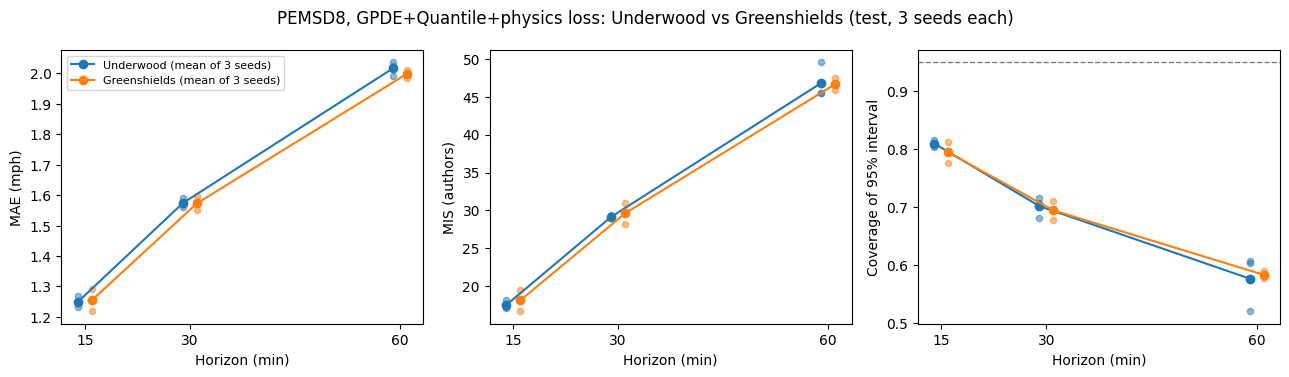

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
P2 = '/content/drive/MyDrive/CS637/p2'; R = f'{P2}/results'
df = pd.read_csv(f'{R}/horizon_metrics.csv')
names = {'pemsd8_underwood_ours': ('Underwood', 0), 'pemsd8_underwood_ours_seed1': ('Underwood', 1),
         'pemsd8_underwood_ours_seed2': ('Underwood', 2), 'pemsd8_greenshields': ('Greenshields', 0),
         'pemsd8_greenshields_seed1': ('Greenshields', 1), 'pemsd8_greenshields_seed2': ('Greenshields', 2)}
t = df[(df['split'] == 'test') & df['label'].isin(names)].copy()
t['physics_law'] = t['label'].map(lambda l: names[l][0]); t['seed'] = t['label'].map(lambda l: names[l][1])
print(t.groupby('physics_law')['seed'].nunique())          # expect 3 and 3
t.to_csv(f'{R}/greenshields_vs_underwood.csv', index=False)

m = ['mae', 'rmse', 'mis_authors', 'coverage', 'width']
s = t[t['view'] == 'step']
summ = s.groupby(['physics_law', 'minutes'])[m].agg(['mean', 'std', 'min', 'max']).round(4)
summ.to_csv(f'{R}/greenshields_vs_underwood_summary.csv')
print(s.groupby(['minutes', 'physics_law'])[m].agg(['mean', 'std']).round(3).to_string())

# same seed number = same initialisation, only the loss differs -> paired differences
p = s.pivot_table(index=['seed', 'minutes'], columns='physics_law', values=m)
d = pd.concat({k: p[k]['Greenshields'] - p[k]['Underwood'] for k in m}, axis=1)
d.round(4).to_csv(f'{R}/greenshields_minus_underwood_paired.csv')
print('\nGreenshields - Underwood, per seed:\n', d.round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, (k, lab) in zip(ax, [('mae', 'MAE (mph)'), ('mis_authors', 'MIS (authors)'), ('coverage', 'Coverage of 95% interval')]):
    for law, c, off in [('Underwood', 'tab:blue', -1), ('Greenshields', 'tab:orange', 1)]:
        g = s[s['physics_law'] == law]
        a.scatter(g['minutes'] + off, g[k], color=c, alpha=0.5, s=20)
        mm = g.groupby('minutes')[k].mean(); a.plot(mm.index + off, mm.values, '-o', color=c, label=f'{law} (mean of 3 seeds)')
    a.set_xticks([15, 30, 60]); a.set_xlabel('Horizon (min)'); a.set_ylabel(lab)
ax[2].axhline(0.95, ls='--', color='grey', lw=1); ax[0].legend(fontsize=8)
fig.suptitle('PEMSD8, GPDE+Quantile+physics loss: Underwood vs Greenshields (test, 3 seeds each)')
fig.tight_layout(); fig.savefig(f'{P2}/figures/pemsd8_greenshields_vs_underwood_3seeds.png', dpi=150)

In [ ]:
import shutil
P2 = '/content/drive/MyDrive/CS637/p2'
CSV = f'{P2}/results/horizon_metrics.csv'
G = '/content/runs/pemsd8_greenshields_seed2'
shutil.copy(f'{G}/train.log', f'{P2}/logs/pemsd8_greenshields_seed2.log')
!python /content/eval_run.py --run {G} --epoch 39 --data_dir /content/data/PEMSD8 \
   --label pemsd8_greenshields_seed2 --law greenshields \
   --vf {P2}/params/greenshields_v_f.npy --k {P2}/params/greenshields_k_jam.npy --csv {CSV}

I0000 00:00:1792671685.594092   31583 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792671687.873592   31583 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 12:21:29,775 - INFO - Log directory: /content/p2_eval_logs/pemsd8_greenshields_seed2
/content/runs/pemsd8_greenshields_seed2/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  L = to

physics_law
Greenshields    3
Underwood       3
Name: seed, dtype: int64
                        mae          rmse        mis_authors        coverage         width       
                       mean    std   mean    std        mean    std     mean    std   mean    std
minutes physics_law                                                                              
15      Greenshields  1.254  0.036  2.703  0.107      17.908  1.478    0.800  0.021  3.438  0.165
        Underwood     1.249  0.018  2.665  0.024      17.528  0.591    0.810  0.006  3.499  0.059
30      Greenshields  1.577  0.024  3.579  0.080      29.357  1.440    0.702  0.022  3.119  0.183
        Underwood     1.574  0.016  3.544  0.013      29.159  0.219    0.701  0.019  3.139  0.064
60      Greenshields  2.009  0.022  4.582  0.071      46.204  1.089    0.593  0.018  2.827  0.212
        Underwood     2.017  0.023  4.576  0.010      46.799  2.341    0.576  0.049  2.782  0.204

Greenshields - Underwood, per seed:
        

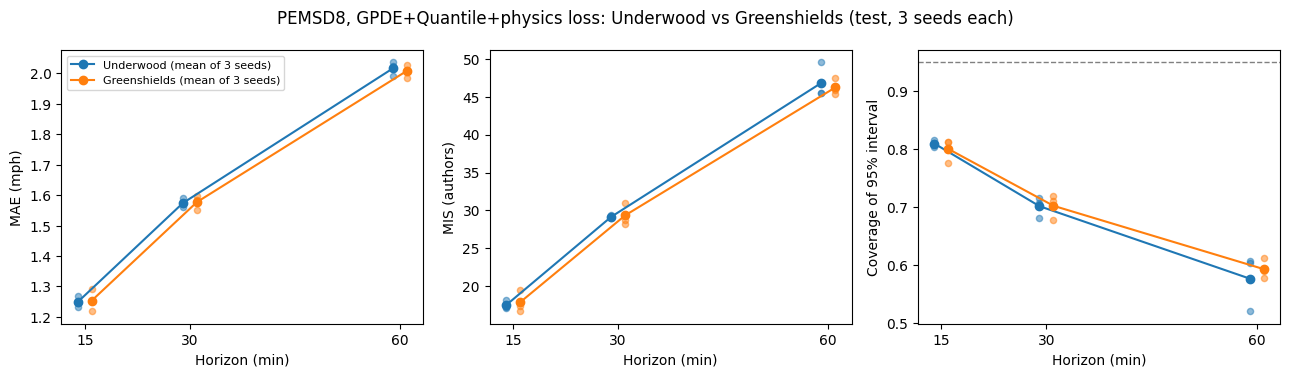

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
P2 = '/content/drive/MyDrive/CS637/p2'; R = f'{P2}/results'
df = pd.read_csv(f'{R}/horizon_metrics.csv')
names = {'pemsd8_underwood_ours': ('Underwood', 0), 'pemsd8_underwood_ours_seed1': ('Underwood', 1),
         'pemsd8_underwood_ours_seed2': ('Underwood', 2), 'pemsd8_greenshields': ('Greenshields', 0),
         'pemsd8_greenshields_seed1': ('Greenshields', 1), 'pemsd8_greenshields_seed2': ('Greenshields', 2)}
t = df[(df['split'] == 'test') & df['label'].isin(names)].copy()
t['physics_law'] = t['label'].map(lambda l: names[l][0]); t['seed'] = t['label'].map(lambda l: names[l][1])
print(t.groupby('physics_law')['seed'].nunique())          # expect 3 and 3
t.to_csv(f'{R}/greenshields_vs_underwood.csv', index=False)

m = ['mae', 'rmse', 'mis_authors', 'coverage', 'width']
s = t[t['view'] == 'step']
summ = s.groupby(['physics_law', 'minutes'])[m].agg(['mean', 'std', 'min', 'max']).round(4)
summ.to_csv(f'{R}/greenshields_vs_underwood_summary.csv')
print(s.groupby(['minutes', 'physics_law'])[m].agg(['mean', 'std']).round(3).to_string())

p = s.pivot_table(index=['seed', 'minutes'], columns='physics_law', values=m)
d = pd.concat({k: p[k]['Greenshields'] - p[k]['Underwood'] for k in m}, axis=1)
d.round(4).to_csv(f'{R}/greenshields_minus_underwood_paired.csv')
print('\nGreenshields - Underwood, per seed:\n', d.round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, (k, lab) in zip(ax, [('mae', 'MAE (mph)'), ('mis_authors', 'MIS (authors)'), ('coverage', 'Coverage of 95% interval')]):
    for law, c, off in [('Underwood', 'tab:blue', -1), ('Greenshields', 'tab:orange', 1)]:
        g = s[s['physics_law'] == law]
        a.scatter(g['minutes'] + off, g[k], color=c, alpha=0.5, s=20)
        mm = g.groupby('minutes')[k].mean(); a.plot(mm.index + off, mm.values, '-o', color=c, label=f'{law} (mean of 3 seeds)')
    a.set_xticks([15, 30, 60]); a.set_xlabel('Horizon (min)'); a.set_ylabel(lab)
ax[2].axhline(0.95, ls='--', color='grey', lw=1); ax[0].legend(fontsize=8)
fig.suptitle('PEMSD8, GPDE+Quantile+physics loss: Underwood vs Greenshields (test, 3 seeds each)')
fig.tight_layout(); fig.savefig(f'{P2}/figures/pemsd8_greenshields_vs_underwood_3seeds.png', dpi=150)
plt.show()

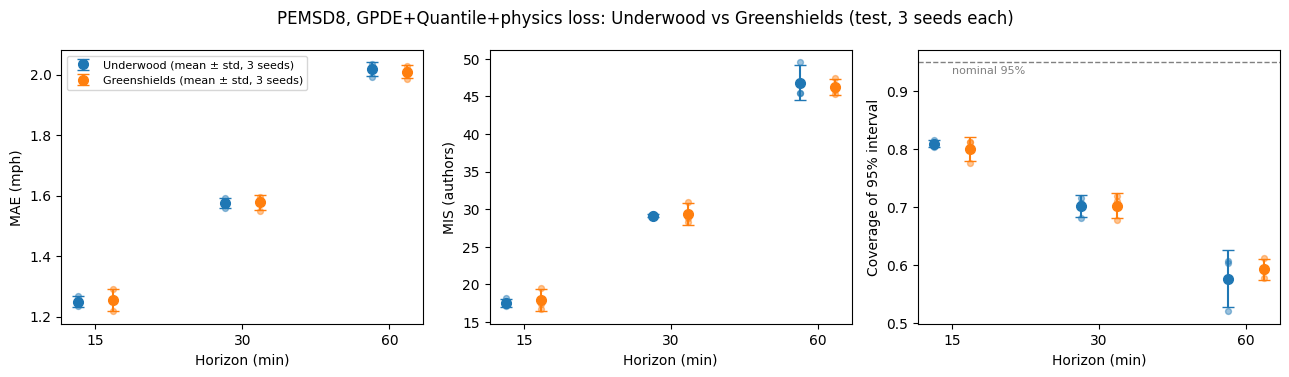

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
H = [15, 30, 60]
for a, (k, lab) in zip(ax, [('mae', 'MAE (mph)'), ('mis_authors', 'MIS (authors)'), ('coverage', 'Coverage of 95% interval')]):
    for law, c, off in [('Underwood', 'tab:blue', -0.12), ('Greenshields', 'tab:orange', 0.12)]:
        g = s[s['physics_law'] == law]
        for i, h in enumerate(H):
            v = g[g['minutes'] == h][k]
            a.scatter([i + off] * len(v), v, color=c, alpha=0.45, s=18)
            a.errorbar(i + off, v.mean(), yerr=v.std(), fmt='o', color=c, capsize=4, ms=7,
                       label=f'{law} (mean ± std, 3 seeds)' if i == 0 else None)
    a.set_xticks(range(3)); a.set_xticklabels(H); a.set_xlabel('Horizon (min)'); a.set_ylabel(lab)
ax[2].axhline(0.95, ls='--', color='grey', lw=1); ax[2].text(0, 0.93, 'nominal 95%', fontsize=8, color='grey')
ax[0].legend(fontsize=8)
fig.suptitle('PEMSD8, GPDE+Quantile+physics loss: Underwood vs Greenshields (test, 3 seeds each)')
fig.tight_layout(); fig.savefig(f'{P2}/figures/pemsd8_greenshields_vs_underwood_3seeds.png', dpi=150)
plt.show()

In [ ]:
import os, glob
P2 = '/content/drive/MyDrive/CS637/p2'
for n, best in [('pemsd8_underwood_ours_seed1', 'epo48.tar'), ('pemsd8_greenshields_seed1', 'epo46.tar')]:
    print(n, '| checkpoint on Drive:', os.path.exists(f'{P2}/checkpoints_seed1/{n}/{best}'),
          '| log on Drive:', os.path.exists(f'{P2}/logs/{n}.log'))

pemsd8_underwood_ours_seed1 | checkpoint on Drive: True | log on Drive: False
pemsd8_greenshields_seed1 | checkpoint on Drive: True | log on Drive: False


In [ ]:
print([f for f in os.listdir(f'{P2}/logs') if 'seed1' in f])

[]


In [ ]:
import shutil, glob, os
from google.colab import files
os.makedirs(f'{P2}/seed1_logs', exist_ok=True)
for n in ['pemsd8_underwood_ours_seed1', 'pemsd8_greenshields_seed1']:
    src = sorted(glob.glob(f'/content/runs/{n}/data/model/*/info.log'))[-1]
    local = f'/content/{n}_log.txt'
    shutil.copy(src, local)
    shutil.copy(src, f'{P2}/seed1_logs/{n}_log.txt')
    print(n, open(src).read().count('val_mae'), 'epochs | backup info.log exists:',
          os.path.exists(f'{P2}/checkpoints_seed1/{n}/info.log'))
    files.download(local)

pemsd8_underwood_ours_seed1 50 epochs | backup info.log exists: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

pemsd8_greenshields_seed1 50 epochs | backup info.log exists: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive; drive.mount('/content/drive')
P2 = '/content/drive/MyDrive/CS637/p2'
src = open(f'{P2}/runs/pemsd8_underwood_ours/model/pytorch/dcrnn_supervisor.py').read()
for name in ['_prepare_data', '_get_x_y', '_get_x_y_in_correct_dims', '_compute_loss']:
    i = src.find(f'def {name}(')
    if i >= 0:
        j = src.find('\n    def ', i + 10)
        print(src[i:j]); print('-' * 60)
for l in src.splitlines():
    if '_compute_loss(' in l or ('import' in l and 'loss' in l):
        print('USE:', l.strip())
print(open(f'{P2}/implementation/physics_losses.py').read())

Mounted at /content/drive
def _prepare_data(self, x, y):
        x, y = self._get_x_y(x, y)
        x, y = self._get_x_y_in_correct_dims(x, y)
        return x.to(device), y.to(device)

------------------------------------------------------------
def _get_x_y(self, x, y):
        """
        :param x: shape (batch_size, seq_len, num_sensor, input_dim)
        :param y: shape (batch_size, horizon, num_sensor, input_dim)
        :returns x shape (seq_len, batch_size, num_sensor, input_dim)
                 y shape (horizon, batch_size, num_sensor, input_dim)
        """
        x = torch.from_numpy(x).float()
        y = torch.from_numpy(y).float()
        self._logger.debug("X: {}".format(x.size()))
        self._logger.debug("y: {}".format(y.size()))
        x = x.permute(1, 0, 2, 3)
        y = y.permute(1, 0, 2, 3)
        return x, y

------------------------------------------------------------
def _get_x_y_in_correct_dims(self, x, y):
        """
        :param x: shape (seq_len, b

In [ ]:
import os, glob, shutil, re, subprocess, requests, zipfile, torch, numpy as np
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
P2 = '/content/drive/MyDrive/CS637/p2'; L = '/content/runs'
print('GPU:', torch.cuda.is_available())

def get_figshare(article_id, name):
    out = f'/content/data/{name}'; os.makedirs(out, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{article_id}/files').json():
        dst = os.path.join(out, f['name'])
        with requests.get(f['download_url'], stream=True) as r:
            r.raise_for_status()
            with open(dst, 'wb') as fh:
                for c in r.iter_content(1 << 20): fh.write(c)
    print(name, sorted(os.listdir(out)))

def make_run(src, name, seed, aligned=False, epochs=None):
    dst = f'{L}/{name}'; shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/{src}', dst,
                    ignore=shutil.ignore_patterns('models*', 'info.log', '__pycache__', 'dcrnn_DR_*', 'gpde_quantile_phy_model_PEMSD8'))
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'; s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    s = re.sub(r'^random_seed = 0\s*$', f'random_seed = {seed}', s, flags=re.M)
    if aligned:
        a1 = "        x, y = self._get_x_y(x, y)\n"
        a2 = "reg* underwood_loss(y_pred, x_true, y_true)"
        assert s.count(a1) == 1 and s.count(a2) == 1, (s.count(a1), s.count(a2))
        s = s.replace(a1, a1 + "        self._y_full = y.to(device)  # time-aligned physics loss: labels incl. future occupancy\n")
        s = s.replace(a2, "reg* underwood_loss(y_pred, self._y_full if os.environ.get('PHYS_ALIGN') == 'future' else x_true, y_true)")
        s = 'import os\n' + s
    open(f, 'w').write(s)
    if epochs:
        c = f'{dst}/data/model/dcrnn_la.yaml'; t = open(c).read()
        t2, n = re.subn(r'(\bepochs:\s*)\d+', rf'\g<1>{epochs}', t); assert n >= 1
        open(c, 'w').write(t2)
    print(name, 'ready (seed', seed, ', aligned' if aligned else '', ')')

def start(jobs, backup):
    cmds = [f"cd {L}/{n} && env -u PHYS_LAW -u PHYS_VF -u PHYS_K -u PHYS_ALIGN {' '.join(f'{k}={v}' for k, v in e.items())} "
            f"python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > train.log 2>&1" for n, e in jobs]
    subprocess.Popen(['bash', '-c', '; '.join(cmds)], start_new_session=True)
    B = f'{P2}/{backup}'; names = ' '.join(n for n, _ in jobs)
    loop = (f'while true; do sleep 300; for n in {names}; do mkdir -p "{B}/$n"; '
            f'cp -u {L}/$n/models/*.tar "{B}/$n/" 2>/dev/null; cp {L}/$n/train.log "{B}/$n/train.log" 2>/dev/null; done; done')
    subprocess.Popen(['bash', '-c', loop], start_new_session=True)
    print('started:', [n for n, _ in jobs])

get_figshare(28347662, 'PEMSD8')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: True
PEMSD8 ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']


In [ ]:
get_figshare(28347830, 'METR-LA')
make_run('pemsd8_underwood_ours', 'pemsd8_underwood_aligned_seed2', 2, aligned=True)
make_run('metrla_gpde_quantile', 'metrla_gpde_quantile_seed1', 1, epochs=25)   # 25 epochs, same as seed 0
start([('pemsd8_underwood_aligned_seed2', {'PHYS_ALIGN': 'future'}),
       ('metrla_gpde_quantile_seed1', {})], 'checkpoints_day2')

METR-LA ['test.npz', 'train.npz', 'val.npz']
pemsd8_underwood_aligned_seed2 ready (seed 2 , aligned )
metrla_gpde_quantile_seed1 ready (seed 1  )
started: ['pemsd8_underwood_aligned_seed2', 'metrla_gpde_quantile_seed1']


In [ ]:
print(os.path.isdir('/content/data/PEMSD8'))
!ps aux | grep "python dcrnn_train" | grep -v grep | wc -l
!grep "val_mae" /content/runs/*/train.log | tail -3

True
1
2026-10-23 11:16:43,616 - INFO - Epoch [27/50] (2744) val_mae:1.5743, val_mis: 28.9281, val_width: 3.4977, val_mse: 12.8353, val_rmse: 3.5826 , 
2026-10-23 11:17:43,628 - INFO - Epoch [28/50] (2842) val_mae:2.4604, val_mis: 49.0126, val_width: 3.6756, val_mse: 17.7121, val_rmse: 4.2086 , 
2026-10-23 11:18:42,782 - INFO - Epoch [29/50] (2940) val_mae:1.7393, val_mis: 31.9906, val_width: 3.5851, val_mse: 12.9275, val_rmse: 3.5955 , 


In [ ]:
script = r'''
import os, re, sys, time, glob, shutil, subprocess
P2, L, delay = sys.argv[1], sys.argv[2], int(sys.argv[3]); names = sys.argv[4:]
CSV = f"{P2}/results/horizon_metrics.csv"
shutil.copy(f"{P2}/implementation/eval_run.py", "/content/eval_run.py")
out = open(f"{P2}/logs/auto_eval_{names[0]}.txt", "a")
def say(m): out.write(time.strftime("%H:%M:%S ") + m + "\n"); out.flush()
def running(d):
    for p in glob.glob("/proc/[0-9]*"):
        try:
            if os.readlink(p + "/cwd") == d and "dcrnn_train" in open(p + "/cmdline").read(): return True
        except Exception: pass
    return False
for name in names:
    d, log = f"{L}/{name}", f"{L}/{name}/train.log"
    while not os.path.exists(log) or running(d): time.sleep(60)
    time.sleep(delay)
    t = open(log).read()
    shutil.copy(log, f"{P2}/logs/{name}_train.log")
    best = re.findall(r"saving to models/epo(\d+)\.tar", t)
    if not best:
        say(f"{name}: no checkpoint saved, last log lines:\n" + "\n".join(t.splitlines()[-15:])); continue
    data = "/content/data/METR-LA" if name.startswith("metrla") else "/content/data/PEMSD8"
    say(f"{name}: training done, {t.count('val_mae')} epochs, best epoch {best[-1]}, evaluating")
    r = subprocess.run(["python", "/content/eval_run.py", "--run", d, "--epoch", best[-1], "--data_dir", data,
                        "--label", name, "--csv", CSV], cwd="/content", capture_output=True, text=True)
    open(f"{P2}/results/eval_output_{name}.txt", "w").write(r.stdout + r.stderr)
    say(f"{name}: eval exit code {r.returncode}\n" + "\n".join(l for l in r.stdout.splitlines() if l[:4] in ("view", "step", "avg ")))
say("all done")
'''
open('/content/auto_eval.py', 'w').write(script)
print('script written')

script written


In [ ]:
subprocess.Popen(['python', '/content/auto_eval.py', P2, L, '120',
                  'pemsd8_underwood_aligned_seed2', 'metrla_gpde_quantile_seed1'], start_new_session=True)
print('auto-eval started')

auto-eval started


In [ ]:
import os, glob
from google.colab import drive
drive.mount('/content/drive')
P2 = '/content/drive/MyDrive/CS637/p2'
for f in ['pemsd8_underwood_aligned', 'pemsd8_underwood_aligned_seed2']:
    p = f'{P2}/logs/auto_eval_{f}.txt'
    print('=' * 20, f); print(open(p).read() if os.path.exists(p) else 'NOT FOUND')
for d in ['checkpoints_aligned', 'checkpoints_day2']:
    for run in sorted(glob.glob(f'{P2}/{d}/*')):
        print(run.split('/')[-1], sorted(os.path.basename(x) for x in glob.glob(f'{run}/*.tar'))[-2:],
              'log epochs:', open(f'{run}/train.log').read().count('val_mae') if os.path.exists(f'{run}/train.log') else '-')

Mounted at /content/drive
==================== pemsd8_underwood_aligned
11:39:53 pemsd8_underwood_aligned: training done, 50 epochs, best epoch 49, evaluating
11:40:46 pemsd8_underwood_aligned: eval exit code 0
view   min     MAE    RMSE      MIS  MIS_std   width  cover
step    15   1.215   2.593   16.370   15.155   3.559  0.815
avg     15   1.026   2.132   11.784   10.759   3.984  0.883
step    30   1.548   3.508   27.814   26.266   3.196  0.716
avg     30   1.237   2.747   18.005   16.769   3.640  0.813
step    60   2.003   4.570   45.721   43.718   2.784  0.589
avg     60   1.530   3.538   28.263   26.732   3.291  0.726

==================== pemsd8_underwood_aligned_seed2
11:41:02 pemsd8_underwood_aligned_seed2: training done, 50 epochs, best epoch 44, evaluating
11:42:05 pemsd8_underwood_aligned_seed2: eval exit code 0
view   min     MAE    RMSE      MIS  MIS_std   width  cover
step    15   1.262   2.662   16.787   15.525   4.081  0.841
avg     15   1.073   2.207   12.358   11.286 

In [ ]:
import os, glob, shutil, re, subprocess, requests, zipfile, torch, numpy as np
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
P2 = '/content/drive/MyDrive/CS637/p2'; L = '/content/runs'
print('GPU:', torch.cuda.is_available())

def get_figshare(article_id, name):
    out = f'/content/data/{name}'; os.makedirs(out, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{article_id}/files').json():
        dst = os.path.join(out, f['name'])
        with requests.get(f['download_url'], stream=True) as r:
            r.raise_for_status()
            with open(dst, 'wb') as fh:
                for c in r.iter_content(1 << 20): fh.write(c)
    print(name, sorted(os.listdir(out)))

def make_run(src, name, seed, aligned=False, epochs=None):
    dst = f'{L}/{name}'; shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/{src}', dst,
                    ignore=shutil.ignore_patterns('models*', 'info.log', '__pycache__', 'dcrnn_DR_*', 'gpde_quantile_phy_model_PEMSD8'))
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'; s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    s = re.sub(r'^random_seed = 0\s*$', f'random_seed = {seed}', s, flags=re.M)
    if aligned:
        a1 = "        x, y = self._get_x_y(x, y)\n"
        a2 = "reg* underwood_loss(y_pred, x_true, y_true)"
        assert s.count(a1) == 1 and s.count(a2) == 1, (s.count(a1), s.count(a2))
        s = s.replace(a1, a1 + "        self._y_full = y.to(device)  # time-aligned physics loss: labels incl. future occupancy\n")
        s = s.replace(a2, "reg* underwood_loss(y_pred, self._y_full if os.environ.get('PHYS_ALIGN') == 'future' else x_true, y_true)")
        s = 'import os\n' + s
    open(f, 'w').write(s)
    if epochs:
        c = f'{dst}/data/model/dcrnn_la.yaml'; t = open(c).read()
        t2, n = re.subn(r'(\bepochs:\s*)\d+', rf'\g<1>{epochs}', t); assert n >= 1
        open(c, 'w').write(t2)
    print(name, 'ready (seed', seed, ', aligned' if aligned else '', ')')

def start(jobs, backup):
    cmds = [f"cd {L}/{n} && env -u PHYS_LAW -u PHYS_VF -u PHYS_K -u PHYS_ALIGN {' '.join(f'{k}={v}' for k, v in e.items())} "
            f"python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > train.log 2>&1" for n, e in jobs]
    subprocess.Popen(['bash', '-c', '; '.join(cmds)], start_new_session=True)
    B = f'{P2}/{backup}'; names = ' '.join(n for n, _ in jobs)
    loop = (f'while true; do sleep 300; for n in {names}; do mkdir -p "{B}/$n"; '
            f'cp -u {L}/$n/models/*.tar "{B}/$n/" 2>/dev/null; cp {L}/$n/train.log "{B}/$n/train.log" 2>/dev/null; done; done')
    subprocess.Popen(['bash', '-c', loop], start_new_session=True)
    print('started:', [n for n, _ in jobs])

script = r'''
import os, re, sys, time, glob, shutil, subprocess
P2, L, delay = sys.argv[1], sys.argv[2], int(sys.argv[3]); names = sys.argv[4:]
CSV = f"{P2}/results/horizon_metrics.csv"
shutil.copy(f"{P2}/implementation/eval_run.py", "/content/eval_run.py")
out = open(f"{P2}/logs/auto_eval_{names[0]}.txt", "a")
def say(m): out.write(time.strftime("%H:%M:%S ") + m + "\n"); out.flush()
def running(d):
    for p in glob.glob("/proc/[0-9]*"):
        try:
            if os.readlink(p + "/cwd") == d and "dcrnn_train" in open(p + "/cmdline").read(): return True
        except Exception: pass
    return False
for name in names:
    d, log = f"{L}/{name}", f"{L}/{name}/train.log"
    while not os.path.exists(log) or running(d): time.sleep(60)
    time.sleep(delay)
    t = open(log).read()
    shutil.copy(log, f"{P2}/logs/{name}_train.log")
    best = re.findall(r"saving to models/epo(\d+)\.tar", t)
    if not best:
        say(f"{name}: no checkpoint saved, last log lines:\n" + "\n".join(t.splitlines()[-15:])); continue
    data = "/content/data/METR-LA" if name.startswith("metrla") else "/content/data/PEMSD8"
    say(f"{name}: training done, {t.count('val_mae')} epochs, best epoch {best[-1]}, evaluating")
    r = subprocess.run(["python", "/content/eval_run.py", "--run", d, "--epoch", best[-1], "--data_dir", data,
                        "--label", name, "--csv", CSV], cwd="/content", capture_output=True, text=True)
    open(f"{P2}/results/eval_output_{name}.txt", "w").write(r.stdout + r.stderr)
    say(f"{name}: eval exit code {r.returncode}\n" + "\n".join(l for l in r.stdout.splitlines() if l[:4] in ("view", "step", "avg ")))
say("all done")
'''
open('/content/auto_eval.py', 'w').write(script)

get_figshare(28347662, 'PEMSD8')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: False
PEMSD8 ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']


In [ ]:
import os, glob, shutil, re, subprocess, requests, zipfile, torch, numpy as np
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
P2 = '/content/drive/MyDrive/CS637/p2'; L = '/content/runs'
print('GPU:', torch.cuda.is_available())

def get_figshare(article_id, name):
    out = f'/content/data/{name}'; os.makedirs(out, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{article_id}/files').json():
        dst = os.path.join(out, f['name'])
        with requests.get(f['download_url'], stream=True) as r:
            r.raise_for_status()
            with open(dst, 'wb') as fh:
                for c in r.iter_content(1 << 20): fh.write(c)
    print(name, sorted(os.listdir(out)))

def make_run(src, name, seed, aligned=False, epochs=None):
    dst = f'{L}/{name}'; shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/{src}', dst,
                    ignore=shutil.ignore_patterns('models*', 'info.log', '__pycache__', 'dcrnn_DR_*', 'gpde_quantile_phy_model_PEMSD8'))
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'; s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    s = re.sub(r'^random_seed = 0\s*$', f'random_seed = {seed}', s, flags=re.M)
    if aligned:
        a1 = "        x, y = self._get_x_y(x, y)\n"
        a2 = "reg* underwood_loss(y_pred, x_true, y_true)"
        assert s.count(a1) == 1 and s.count(a2) == 1, (s.count(a1), s.count(a2))
        s = s.replace(a1, a1 + "        self._y_full = y.to(device)  # time-aligned physics loss: labels incl. future occupancy\n")
        s = s.replace(a2, "reg* underwood_loss(y_pred, self._y_full if os.environ.get('PHYS_ALIGN') == 'future' else x_true, y_true)")
        s = 'import os\n' + s
    open(f, 'w').write(s)
    if epochs:
        c = f'{dst}/data/model/dcrnn_la.yaml'; t = open(c).read()
        t2, n = re.subn(r'(\bepochs:\s*)\d+', rf'\g<1>{epochs}', t); assert n >= 1
        open(c, 'w').write(t2)
    print(name, 'ready (seed', seed, ', aligned' if aligned else '', ')')

def start(jobs, backup):
    cmds = [f"cd {L}/{n} && env -u PHYS_LAW -u PHYS_VF -u PHYS_K -u PHYS_ALIGN {' '.join(f'{k}={v}' for k, v in e.items())} "
            f"python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > train.log 2>&1" for n, e in jobs]
    subprocess.Popen(['bash', '-c', '; '.join(cmds)], start_new_session=True)
    B = f'{P2}/{backup}'; names = ' '.join(n for n, _ in jobs)
    loop = (f'while true; do sleep 300; for n in {names}; do mkdir -p "{B}/$n"; '
            f'cp -u {L}/$n/models/*.tar "{B}/$n/" 2>/dev/null; cp {L}/$n/train.log "{B}/$n/train.log" 2>/dev/null; done; done')
    subprocess.Popen(['bash', '-c', loop], start_new_session=True)
    print('started:', [n for n, _ in jobs])

script = r'''
import os, re, sys, time, glob, shutil, subprocess
P2, L, delay = sys.argv[1], sys.argv[2], int(sys.argv[3]); names = sys.argv[4:]
CSV = f"{P2}/results/horizon_metrics.csv"
shutil.copy(f"{P2}/implementation/eval_run.py", "/content/eval_run.py")
out = open(f"{P2}/logs/auto_eval_{names[0]}.txt", "a")
def say(m): out.write(time.strftime("%H:%M:%S ") + m + "\n"); out.flush()
def running(d):
    for p in glob.glob("/proc/[0-9]*"):
        try:
            if os.readlink(p + "/cwd") == d and "dcrnn_train" in open(p + "/cmdline").read(): return True
        except Exception: pass
    return False
for name in names:
    d, log = f"{L}/{name}", f"{L}/{name}/train.log"
    while not os.path.exists(log) or running(d): time.sleep(60)
    time.sleep(delay)
    t = open(log).read()
    shutil.copy(log, f"{P2}/logs/{name}_train.log")
    best = re.findall(r"saving to models/epo(\d+)\.tar", t)
    if not best:
        say(f"{name}: no checkpoint saved, last log lines:\n" + "\n".join(t.splitlines()[-15:])); continue
    data = "/content/data/METR-LA" if name.startswith("metrla") else "/content/data/PEMSD8"
    say(f"{name}: training done, {t.count('val_mae')} epochs, best epoch {best[-1]}, evaluating")
    r = subprocess.run(["python", "/content/eval_run.py", "--run", d, "--epoch", best[-1], "--data_dir", data,
                        "--label", name, "--csv", CSV], cwd="/content", capture_output=True, text=True)
    open(f"{P2}/results/eval_output_{name}.txt", "w").write(r.stdout + r.stderr)
    say(f"{name}: eval exit code {r.returncode}\n" + "\n".join(l for l in r.stdout.splitlines() if l[:4] in ("view", "step", "avg ")))
say("all done")
'''
open('/content/auto_eval.py', 'w').write(script)

get_figshare(28347662, 'PEMSD8')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: False


KeyboardInterrupt: 

In [ ]:
get_figshare(28347830, 'METR-LA')
make_run('pemsd8_underwood_ours', 'pemsd8_underwood_aligned_seed1', 1, aligned=True)
make_run('metrla_gpde_quantile_phy', 'metrla_gpde_quantile_phy_seed1', 1, epochs=25)
start([('pemsd8_underwood_aligned_seed1', {'PHYS_ALIGN': 'future'}),
       ('metrla_gpde_quantile_phy_seed1', {})], 'checkpoints_day3')
subprocess.Popen(['python', '/content/auto_eval.py', P2, L, '0',
                  'pemsd8_underwood_aligned_seed1', 'metrla_gpde_quantile_phy_seed1'], start_new_session=True)
print('auto-eval started')

In [ ]:
get_figshare(28347830, 'METR-LA')
make_run('metrla_gpde_quantile', 'metrla_gpde_quantile_seed1', 1, epochs=25)
start([('metrla_gpde_quantile_seed1', {})], 'checkpoints_day3')
subprocess.Popen(['python', '/content/auto_eval.py', P2, L, '120', 'metrla_gpde_quantile_seed1'], start_new_session=True)
print('auto-eval started')

In [ ]:
from google.colab import drive; drive.mount('/content/drive')
import os; print(os.path.isdir('/content/drive/MyDrive/CS637/p2'))

Mounted at /content/drive
True


In [ ]:
import os, glob, shutil, re, subprocess, requests, zipfile, torch, numpy as np
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
P2 = '/content/drive/MyDrive/CS637/p2'; L = '/content/runs'
print('GPU:', torch.cuda.is_available())

def get_figshare(article_id, name):
    out = f'/content/data/{name}'; os.makedirs(out, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{article_id}/files').json():
        dst = os.path.join(out, f['name'])
        with requests.get(f['download_url'], stream=True) as r:
            r.raise_for_status()
            with open(dst, 'wb') as fh:
                for c in r.iter_content(1 << 20): fh.write(c)
    print(name, sorted(os.listdir(out)))

def make_run(src, name, seed, aligned=False, epochs=None):
    dst = f'{L}/{name}'; shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/{src}', dst,
                    ignore=shutil.ignore_patterns('models*', 'info.log', '__pycache__', 'dcrnn_DR_*', 'gpde_quantile_phy_model_PEMSD8'))
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'; s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    s = re.sub(r'^random_seed = 0\s*$', f'random_seed = {seed}', s, flags=re.M)
    if aligned:
        a1 = "        x, y = self._get_x_y(x, y)\n"
        a2 = "reg* underwood_loss(y_pred, x_true, y_true)"
        assert s.count(a1) == 1 and s.count(a2) == 1, (s.count(a1), s.count(a2))
        s = s.replace(a1, a1 + "        self._y_full = y.to(device)  # time-aligned physics loss: labels incl. future occupancy\n")
        s = s.replace(a2, "reg* underwood_loss(y_pred, self._y_full if os.environ.get('PHYS_ALIGN') == 'future' else x_true, y_true)")
        s = 'import os\n' + s
    open(f, 'w').write(s)
    if epochs:
        c = f'{dst}/data/model/dcrnn_la.yaml'; t = open(c).read()
        t2, n = re.subn(r'(\bepochs:\s*)\d+', rf'\g<1>{epochs}', t); assert n >= 1
        open(c, 'w').write(t2)
    print(name, 'ready (seed', seed, ', aligned' if aligned else '', ')')

def start(jobs, backup):
    cmds = [f"cd {L}/{n} && env -u PHYS_LAW -u PHYS_VF -u PHYS_K -u PHYS_ALIGN {' '.join(f'{k}={v}' for k, v in e.items())} "
            f"python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > train.log 2>&1" for n, e in jobs]
    subprocess.Popen(['bash', '-c', '; '.join(cmds)], start_new_session=True)
    B = f'{P2}/{backup}'; names = ' '.join(n for n, _ in jobs)
    loop = (f'while true; do sleep 300; for n in {names}; do mkdir -p "{B}/$n"; '
            f'cp -u {L}/$n/models/*.tar "{B}/$n/" 2>/dev/null; cp {L}/$n/train.log "{B}/$n/train.log" 2>/dev/null; done; done')
    subprocess.Popen(['bash', '-c', loop], start_new_session=True)
    print('started:', [n for n, _ in jobs])

script = r'''
import os, re, sys, time, glob, shutil, subprocess
P2, L, delay = sys.argv[1], sys.argv[2], int(sys.argv[3]); names = sys.argv[4:]
CSV = f"{P2}/results/horizon_metrics.csv"
shutil.copy(f"{P2}/implementation/eval_run.py", "/content/eval_run.py")
out = open(f"{P2}/logs/auto_eval_{names[0]}.txt", "a")
def say(m): out.write(time.strftime("%H:%M:%S ") + m + "\n"); out.flush()
def running(d):
    for p in glob.glob("/proc/[0-9]*"):
        try:
            if os.readlink(p + "/cwd") == d and "dcrnn_train" in open(p + "/cmdline").read(): return True
        except Exception: pass
    return False
for name in names:
    d, log = f"{L}/{name}", f"{L}/{name}/train.log"
    while not os.path.exists(log) or running(d): time.sleep(60)
    time.sleep(delay)
    t = open(log).read()
    shutil.copy(log, f"{P2}/logs/{name}_train.log")
    best = re.findall(r"saving to models/epo(\d+)\.tar", t)
    if not best:
        say(f"{name}: no checkpoint saved, last log lines:\n" + "\n".join(t.splitlines()[-15:])); continue
    data = "/content/data/METR-LA" if name.startswith("metrla") else "/content/data/PEMSD8"
    say(f"{name}: training done, {t.count('val_mae')} epochs, best epoch {best[-1]}, evaluating")
    r = subprocess.run(["python", "/content/eval_run.py", "--run", d, "--epoch", best[-1], "--data_dir", data,
                        "--label", name, "--csv", CSV], cwd="/content", capture_output=True, text=True)
    open(f"{P2}/results/eval_output_{name}.txt", "w").write(r.stdout + r.stderr)
    say(f"{name}: eval exit code {r.returncode}\n" + "\n".join(l for l in r.stdout.splitlines() if l[:4] in ("view", "step", "avg ")))
say("all done")
'''
open('/content/auto_eval.py', 'w').write(script)

get_figshare(28347662, 'PEMSD8')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: True
PEMSD8 ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']


In [ ]:
make_run('pemsd8_underwood_ours', 'pemsd8_underwood_aligned_seed1', 1, aligned=True)
start([('pemsd8_underwood_aligned_seed1', {'PHYS_ALIGN': 'future'})], 'checkpoints_day3')
subprocess.Popen(['python', '/content/auto_eval.py', P2, L, '0', 'pemsd8_underwood_aligned_seed1'], start_new_session=True)
print('auto-eval started')

pemsd8_underwood_aligned_seed1 ready (seed 1 , aligned )
started: ['pemsd8_underwood_aligned_seed1']
auto-eval started


In [ ]:
!ps aux | grep "python dcrnn_train" | grep -v grep | wc -l
!grep val_mae /content/runs/pemsd8_underwood_aligned_seed1/train.log | tail -2

1
2026-10-24 06:59:09,590 - INFO - Epoch [13/50] (1372) val_mae:1.7849, val_mis: 29.5205, val_width: 4.9041, val_mse: 14.6744, val_rmse: 3.8307 , 
2026-10-24 07:00:10,819 - INFO - Epoch [14/50] (1470) val_mae:1.6747, val_mis: 29.4093, val_width: 3.9549, val_mse: 13.7699, val_rmse: 3.7108 , 


In [ ]:
print(open(f'{P2}/logs/auto_eval_pemsd8_underwood_aligned_seed1.txt').read())

NameError: name 'P2' is not defined

In [ ]:
import os, glob
from google.colab import drive
drive.mount('/content/drive')
P2 = '/content/drive/MyDrive/CS637/p2'
f = f'{P2}/logs/auto_eval_pemsd8_underwood_aligned_seed1.txt'
print(open(f).read() if os.path.exists(f) else 'auto-eval file NOT FOUND')
b = f'{P2}/checkpoints_day3/pemsd8_underwood_aligned_seed1'
if os.path.isdir(b):
    t = open(f'{b}/train.log').read() if os.path.exists(f'{b}/train.log') else ''
    print('backup: epochs in log', t.count('val_mae'), '| checkpoints',
          sorted(glob.glob(f'{b}/*.tar'), key=lambda p: int(p.split('epo')[-1][:-4]))[-1:])

Mounted at /content/drive

backup: epochs in log 33 | checkpoints ['/content/drive/MyDrive/CS637/p2/checkpoints_day3/pemsd8_underwood_aligned_seed1/epo32.tar']


In [ ]:
import os, glob, shutil, re, subprocess, requests, zipfile, torch, numpy as np
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
P2 = '/content/drive/MyDrive/CS637/p2'; L = '/content/runs'
print('GPU:', torch.cuda.is_available())

def get_figshare(article_id, name):
    out = f'/content/data/{name}'; os.makedirs(out, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{article_id}/files').json():
        dst = os.path.join(out, f['name'])
        with requests.get(f['download_url'], stream=True) as r:
            r.raise_for_status()
            with open(dst, 'wb') as fh:
                for c in r.iter_content(1 << 20): fh.write(c)
    print(name, sorted(os.listdir(out)))

def make_run(src, name, seed, aligned=False, epochs=None):
    dst = f'{L}/{name}'; shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/{src}', dst,
                    ignore=shutil.ignore_patterns('models*', 'info.log', '__pycache__', 'dcrnn_DR_*', 'gpde_quantile_phy_model_PEMSD8'))
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'; s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    s = re.sub(r'^random_seed = 0\s*$', f'random_seed = {seed}', s, flags=re.M)
    if aligned:
        a1 = "        x, y = self._get_x_y(x, y)\n"
        a2 = "reg* underwood_loss(y_pred, x_true, y_true)"
        assert s.count(a1) == 1 and s.count(a2) == 1, (s.count(a1), s.count(a2))
        s = s.replace(a1, a1 + "        self._y_full = y.to(device)  # time-aligned physics loss: labels incl. future occupancy\n")
        s = s.replace(a2, "reg* underwood_loss(y_pred, self._y_full if os.environ.get('PHYS_ALIGN') == 'future' else x_true, y_true)")
        s = 'import os\n' + s
    open(f, 'w').write(s)
    if epochs:
        c = f'{dst}/data/model/dcrnn_la.yaml'; t = open(c).read()
        t2, n = re.subn(r'(\bepochs:\s*)\d+', rf'\g<1>{epochs}', t); assert n >= 1
        open(c, 'w').write(t2)
    print(name, 'ready (seed', seed, ', aligned' if aligned else '', ')')

def start(jobs, backup):
    cmds = [f"cd {L}/{n} && env -u PHYS_LAW -u PHYS_VF -u PHYS_K -u PHYS_ALIGN {' '.join(f'{k}={v}' for k, v in e.items())} "
            f"python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > train.log 2>&1" for n, e in jobs]
    subprocess.Popen(['bash', '-c', '; '.join(cmds)], start_new_session=True)
    B = f'{P2}/{backup}'; names = ' '.join(n for n, _ in jobs)
    loop = (f'while true; do sleep 300; for n in {names}; do mkdir -p "{B}/$n"; '
            f'cp -u {L}/$n/models/*.tar "{B}/$n/" 2>/dev/null; cp {L}/$n/train.log "{B}/$n/train.log" 2>/dev/null; done; done')
    subprocess.Popen(['bash', '-c', loop], start_new_session=True)
    print('started:', [n for n, _ in jobs])

script = r'''
import os, re, sys, time, glob, shutil, subprocess
P2, L, delay = sys.argv[1], sys.argv[2], int(sys.argv[3]); names = sys.argv[4:]
CSV = f"{P2}/results/horizon_metrics.csv"
shutil.copy(f"{P2}/implementation/eval_run.py", "/content/eval_run.py")
out = open(f"{P2}/logs/auto_eval_{names[0]}.txt", "a")
def say(m): out.write(time.strftime("%H:%M:%S ") + m + "\n"); out.flush()
def running(d):
    for p in glob.glob("/proc/[0-9]*"):
        try:
            if os.readlink(p + "/cwd") == d and "dcrnn_train" in open(p + "/cmdline").read(): return True
        except Exception: pass
    return False
for name in names:
    d, log = f"{L}/{name}", f"{L}/{name}/train.log"
    while not os.path.exists(log) or running(d): time.sleep(60)
    time.sleep(delay)
    t = open(log).read()
    shutil.copy(log, f"{P2}/logs/{name}_train.log")
    best = re.findall(r"saving to models/epo(\d+)\.tar", t)
    if not best:
        say(f"{name}: no checkpoint saved, last log lines:\n" + "\n".join(t.splitlines()[-15:])); continue
    data = "/content/data/METR-LA" if name.startswith("metrla") else "/content/data/PEMSD8"
    say(f"{name}: training done, {t.count('val_mae')} epochs, best epoch {best[-1]}, evaluating")
    r = subprocess.run(["python", "/content/eval_run.py", "--run", d, "--epoch", best[-1], "--data_dir", data,
                        "--label", name, "--csv", CSV], cwd="/content", capture_output=True, text=True)
    open(f"{P2}/results/eval_output_{name}.txt", "w").write(r.stdout + r.stderr)
    say(f"{name}: eval exit code {r.returncode}\n" + "\n".join(l for l in r.stdout.splitlines() if l[:4] in ("view", "step", "avg ")))
say("all done")
'''
open('/content/auto_eval.py', 'w').write(script)

get_figshare(28347662, 'PEMSD8')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: True
PEMSD8 ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']


In [ ]:
make_run('pemsd8_underwood_ours', 'pemsd8_underwood_aligned_seed1', 1, aligned=True)
start([('pemsd8_underwood_aligned_seed1', {'PHYS_ALIGN': 'future'})], 'checkpoints_day3b')
subprocess.Popen(['python', '/content/auto_eval.py', P2, L, '0', 'pemsd8_underwood_aligned_seed1'], start_new_session=True)
print('auto-eval started')

pemsd8_underwood_aligned_seed1 ready (seed 1 , aligned )
started: ['pemsd8_underwood_aligned_seed1']
auto-eval started


In [ ]:
import os, glob, subprocess
P2 = '/content/drive/MyDrive/CS637/p2'
print('GPU runtime:', subprocess.run('nvidia-smi -L', shell=True, capture_output=True, text=True).stdout.strip() or 'none (CPU)')
print('training processes:', subprocess.run('ps aux | grep "python dcrnn_train" | grep -v grep | wc -l',
                                             shell=True, capture_output=True, text=True).stdout.strip())
log = '/content/runs/pemsd8_underwood_aligned_seed1/train.log'
if os.path.exists(log):
    t = open(log).read().splitlines()
    print('epochs so far:', sum('val_mae' in l for l in t))
    print('\n'.join(l for l in t if 'val_mae' in l][-2:]) if False else [l for l in t if 'val_mae' in l][-2:])
else:
    print('no training log on this runtime')
print('partial eval rows in CSV:', open(f'{P2}/results/horizon_metrics.csv').read().count('aligned_seed1_partial33'))

SyntaxError: closing parenthesis ']' does not match opening parenthesis '(' (4054660163.py, line 10)

In [ ]:
import os, glob, subprocess
P2 = '/content/drive/MyDrive/CS637/p2'
print('GPU runtime:', subprocess.run('nvidia-smi -L', shell=True, capture_output=True, text=True).stdout.strip() or 'none (CPU)')
print('training processes:', subprocess.run('ps aux | grep "python dcrnn_train" | grep -v grep | wc -l',
                                             shell=True, capture_output=True, text=True).stdout.strip())
log = '/content/runs/pemsd8_underwood_aligned_seed1/train.log'
if os.path.exists(log):
    lines = [l for l in open(log).read().splitlines() if 'val_mae' in l]
    print('epochs so far:', len(lines))
    for l in lines[-2:]:
        print(l)
else:
    print('no training log on this runtime')
print('partial eval rows in CSV:', open(f'{P2}/results/horizon_metrics.csv').read().count('aligned_seed1_partial33'))
af = f'{P2}/logs/auto_eval_pemsd8_underwood_aligned_seed1.txt'
print(open(af).read() if os.path.exists(af) else 'no auto-eval file yet')

GPU runtime: GPU 0: Tesla T4 (UUID: GPU-2c4290fb-30b5-ff33-cb1e-7ad4cad3d011)
training processes: 0
no training log on this runtime


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/CS637/p2/results/horizon_metrics.csv'

In [ ]:
import os; print('drive mounted:', os.path.ismount('/content/drive'), '| PEMSD8 data:', os.path.isdir('/content/data/PEMSD8'))

drive mounted: False | PEMSD8 data: False


In [ ]:
import os, glob
from google.colab import drive
drive.mount('/content/drive')
P2 = '/content/drive/MyDrive/CS637/p2'

af = f'{P2}/logs/auto_eval_pemsd8_underwood_aligned_seed1.txt'
print('1) auto-eval result:\n', open(af).read() if os.path.exists(af) else '   none')

csv = open(f'{P2}/results/horizon_metrics.csv').read()
print('2) rows in results CSV: full run', csv.count('pemsd8_underwood_aligned_seed1,'),
      '| partial', csv.count('aligned_seed1_partial33'))

for d in ['checkpoints_day3', 'checkpoints_day3b']:
    b = f'{P2}/{d}/pemsd8_underwood_aligned_seed1'
    if os.path.isdir(b):
        n = open(f'{b}/train.log').read().count('val_mae') if os.path.exists(f'{b}/train.log') else 0
        tars = sorted(glob.glob(f'{b}/*.tar'), key=lambda p: int(p.split('epo')[-1][:-4]))
        print(f'3) {d}: {n} epochs in log, best checkpoint {os.path.basename(tars[-1]) if tars else "none"}')
    else:
        print(f'3) {d}: not there')

Mounted at /content/drive
1) auto-eval result:
 
2) rows in results CSV: full run 0 | partial 0
3) checkpoints_day3: 33 epochs in log, best checkpoint epo32.tar
3) checkpoints_day3b: 37 epochs in log, best checkpoint epo35.tar


In [ ]:
import os, glob, shutil, re, subprocess, requests, zipfile, torch, numpy as np
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
P2 = '/content/drive/MyDrive/CS637/p2'; L = '/content/runs'
print('GPU:', torch.cuda.is_available())

def get_figshare(article_id, name):
    out = f'/content/data/{name}'; os.makedirs(out, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{article_id}/files').json():
        dst = os.path.join(out, f['name'])
        with requests.get(f['download_url'], stream=True) as r:
            r.raise_for_status()
            with open(dst, 'wb') as fh:
                for c in r.iter_content(1 << 20): fh.write(c)
    print(name, sorted(os.listdir(out)))

def make_run(src, name, seed, aligned=False, epochs=None):
    dst = f'{L}/{name}'; shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/{src}', dst,
                    ignore=shutil.ignore_patterns('models*', 'info.log', '__pycache__', 'dcrnn_DR_*', 'gpde_quantile_phy_model_PEMSD8'))
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'; s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    s = re.sub(r'^random_seed = 0\s*$', f'random_seed = {seed}', s, flags=re.M)
    if aligned:
        a1 = "        x, y = self._get_x_y(x, y)\n"
        a2 = "reg* underwood_loss(y_pred, x_true, y_true)"
        assert s.count(a1) == 1 and s.count(a2) == 1, (s.count(a1), s.count(a2))
        s = s.replace(a1, a1 + "        self._y_full = y.to(device)  # time-aligned physics loss: labels incl. future occupancy\n")
        s = s.replace(a2, "reg* underwood_loss(y_pred, self._y_full if os.environ.get('PHYS_ALIGN') == 'future' else x_true, y_true)")
        s = 'import os\n' + s
    open(f, 'w').write(s)
    if epochs:
        c = f'{dst}/data/model/dcrnn_la.yaml'; t = open(c).read()
        t2, n = re.subn(r'(\bepochs:\s*)\d+', rf'\g<1>{epochs}', t); assert n >= 1
        open(c, 'w').write(t2)
    print(name, 'ready (seed', seed, ', aligned' if aligned else '', ')')

def start(jobs, backup):
    cmds = [f"cd {L}/{n} && env -u PHYS_LAW -u PHYS_VF -u PHYS_K -u PHYS_ALIGN {' '.join(f'{k}={v}' for k, v in e.items())} "
            f"python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > train.log 2>&1" for n, e in jobs]
    subprocess.Popen(['bash', '-c', '; '.join(cmds)], start_new_session=True)
    B = f'{P2}/{backup}'; names = ' '.join(n for n, _ in jobs)
    loop = (f'while true; do sleep 300; for n in {names}; do mkdir -p "{B}/$n"; '
            f'cp -u {L}/$n/models/*.tar "{B}/$n/" 2>/dev/null; cp {L}/$n/train.log "{B}/$n/train.log" 2>/dev/null; done; done')
    subprocess.Popen(['bash', '-c', loop], start_new_session=True)
    print('started:', [n for n, _ in jobs])

script = r'''
import os, re, sys, time, glob, shutil, subprocess
P2, L, delay = sys.argv[1], sys.argv[2], int(sys.argv[3]); names = sys.argv[4:]
CSV = f"{P2}/results/horizon_metrics.csv"
shutil.copy(f"{P2}/implementation/eval_run.py", "/content/eval_run.py")
out = open(f"{P2}/logs/auto_eval_{names[0]}.txt", "a")
def say(m): out.write(time.strftime("%H:%M:%S ") + m + "\n"); out.flush()
def running(d):
    for p in glob.glob("/proc/[0-9]*"):
        try:
            if os.readlink(p + "/cwd") == d and "dcrnn_train" in open(p + "/cmdline").read(): return True
        except Exception: pass
    return False
for name in names:
    d, log = f"{L}/{name}", f"{L}/{name}/train.log"
    while not os.path.exists(log) or running(d): time.sleep(60)
    time.sleep(delay)
    t = open(log).read()
    shutil.copy(log, f"{P2}/logs/{name}_train.log")
    best = re.findall(r"saving to models/epo(\d+)\.tar", t)
    if not best:
        say(f"{name}: no checkpoint saved, last log lines:\n" + "\n".join(t.splitlines()[-15:])); continue
    data = "/content/data/METR-LA" if name.startswith("metrla") else "/content/data/PEMSD8"
    say(f"{name}: training done, {t.count('val_mae')} epochs, best epoch {best[-1]}, evaluating")
    r = subprocess.run(["python", "/content/eval_run.py", "--run", d, "--epoch", best[-1], "--data_dir", data,
                        "--label", name, "--csv", CSV], cwd="/content", capture_output=True, text=True)
    open(f"{P2}/results/eval_output_{name}.txt", "w").write(r.stdout + r.stderr)
    say(f"{name}: eval exit code {r.returncode}\n" + "\n".join(l for l in r.stdout.splitlines() if l[:4] in ("view", "step", "avg ")))
say("all done")
'''
open('/content/auto_eval.py', 'w').write(script)

get_figshare(28347662, 'PEMSD8')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: True
PEMSD8 ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']


In [ ]:
# fallback: evaluate the 37-epoch run (best epoch 35), clearly labelled as partial
pname = 'pemsd8_underwood_aligned_seed1_partial'
make_run('pemsd8_underwood_ours', pname, 1, aligned=True)
shutil.copy(f'{P2}/checkpoints_day3b/pemsd8_underwood_aligned_seed1/epo35.tar', f'{L}/{pname}/models/')
shutil.copy(f'{P2}/implementation/eval_run.py', '/content/eval_run.py')
!python /content/eval_run.py --run {L}/{pname} --epoch 35 --data_dir /content/data/PEMSD8 \
   --label pemsd8_underwood_aligned_seed1_partial37 --csv {P2}/results/horizon_metrics.csv

# full run, third attempt
make_run('pemsd8_underwood_ours', 'pemsd8_underwood_aligned_seed1', 1, aligned=True)
start([('pemsd8_underwood_aligned_seed1', {'PHYS_ALIGN': 'future'})], 'checkpoints_day3c')
subprocess.Popen(['python', '/content/auto_eval.py', P2, L, '0', 'pemsd8_underwood_aligned_seed1'], start_new_session=True)
print('auto-eval started')

pemsd8_underwood_aligned_seed1_partial ready (seed 1 , aligned )
I0000 00:00:1792832824.088207    6031 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792832826.254707    6031 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-24 09:07:08,411 - INFO - Log directory: /content/p2_eval_logs/pemsd8_underwood_aligned_seed1_partial37
/content/runs/pemsd8_underwood_aligned_seed1_partial/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc

In [ ]:
import subprocess
log = '/content/runs/pemsd8_underwood_aligned_seed1/train.log'
lines = [l for l in open(log).read().splitlines() if 'val_mae' in l]
saves = [l for l in open(log).read().splitlines() if 'saving to' in l]
print('training processes:', subprocess.run('ps aux | grep "python dcrnn_train" | grep -v grep | wc -l',
                                             shell=True, capture_output=True, text=True).stdout.strip())
print(f'{len(lines)} of 50 epochs done')
print('best so far:', saves[-1].split('saving to ')[-1] if saves else 'none')
print(lines[-1][:120])

training processes: 1
34 of 50 epochs done
best so far: models/epo32.tar
2026-10-24 09:41:28,238 - INFO - Epoch [33/50] (3332) val_mae:1.7903, val_mis: 32.4811, val_width: 3.7106, val_mse: 13.1


In [ ]:
import subprocess
log = '/content/runs/pemsd8_underwood_aligned_seed1/train.log'
lines = [l for l in open(log).read().splitlines() if 'val_mae' in l]
saves = [l for l in open(log).read().splitlines() if 'saving to' in l]
print('training processes:', subprocess.run('ps aux | grep "python dcrnn_train" | grep -v grep | wc -l',
                                             shell=True, capture_output=True, text=True).stdout.strip())
print(f'{len(lines)} of 50 epochs done')
print('best so far:', saves[-1].split('saving to ')[-1] if saves else 'none')
print(lines[-1][:120])

training processes: 1
49 of 50 epochs done
best so far: models/epo48.tar
2026-10-24 09:56:27,764 - INFO - Epoch [48/50] (4802) val_mae:1.5397, val_mis: 28.8320, val_width: 3.2689, val_mse: 12.6


In [ ]:
print(open(f'{P2}/logs/auto_eval_pemsd8_underwood_aligned_seed1.txt').read())

09:58:26 pemsd8_underwood_aligned_seed1: training done, 50 epochs, best epoch 48, evaluating
09:58:47 pemsd8_underwood_aligned_seed1: eval exit code 0
view   min     MAE    RMSE      MIS  MIS_std   width  cover
step    15   1.238   2.628   17.658   16.420   3.396  0.795
avg     15   1.054   2.185   12.728   11.674   3.827  0.865
step    30   1.561   3.519   28.739   27.178   3.154  0.703
avg     30   1.259   2.777   19.040   17.781   3.519  0.797
step    60   2.004   4.606   44.410   42.406   3.054  0.620
avg     60   1.544   3.562   28.632   27.088   3.299  0.723
09:58:47 all done



In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
P2 = '/content/drive/MyDrive/CS637/p2'; R = f'{P2}/results'
df = pd.read_csv(f'{R}/horizon_metrics.csv')
names = {'pemsd8_underwood_ours': ('Underwood (authors)', 0), 'pemsd8_underwood_ours_seed1': ('Underwood (authors)', 1),
         'pemsd8_underwood_ours_seed2': ('Underwood (authors)', 2), 'pemsd8_underwood_aligned': ('Time-aligned', 0),
         'pemsd8_underwood_aligned_seed1': ('Time-aligned', 1), 'pemsd8_underwood_aligned_seed2': ('Time-aligned', 2)}
t = df[(df['split'] == 'test') & df['label'].isin(names)].drop_duplicates(['label', 'view', 'minutes'], keep='last').copy()
t['variant'] = t['label'].map(lambda l: names[l][0]); t['seed'] = t['label'].map(lambda l: names[l][1])
print(t.groupby('variant')['seed'].nunique())          # expect 3 and 3
t.to_csv(f'{R}/time_aligned_vs_underwood.csv', index=False)

m = ['mae', 'rmse', 'mis_authors', 'coverage', 'width']
s = t[t['view'] == 'step']
s.groupby(['variant', 'minutes'])[m].agg(['mean', 'std', 'min', 'max']).round(4).to_csv(f'{R}/time_aligned_vs_underwood_summary.csv')
print(s.groupby(['minutes', 'variant'])[m].agg(['mean', 'std']).round(3).to_string())
p = s.pivot_table(index=['seed', 'minutes'], columns='variant', values=m)
d = pd.concat({k: p[k]['Time-aligned'] - p[k]['Underwood (authors)'] for k in m}, axis=1)
d.round(4).to_csv(f'{R}/time_aligned_minus_underwood_paired.csv')
print('\nTime-aligned - Underwood, per seed:\n', d.round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8)); H = [15, 30, 60]
for a, (k, lab) in zip(ax, [('mae', 'MAE (mph)'), ('mis_authors', 'MIS (authors)'), ('coverage', 'Coverage of 95% interval')]):
    for var, c, off in [('Underwood (authors)', 'tab:blue', -0.12), ('Time-aligned', 'tab:green', 0.12)]:
        g = s[s['variant'] == var]
        for i, h in enumerate(H):
            v = g[g['minutes'] == h][k]
            a.scatter([i + off] * len(v), v, color=c, alpha=0.45, s=18)
            a.errorbar(i + off, v.mean(), yerr=v.std(), fmt='o', color=c, capsize=4, ms=7,
                       label=f'{var} (mean ± std, 3 seeds)' if i == 0 else None)
    a.set_xticks(range(3)); a.set_xticklabels(H); a.set_xlabel('Horizon (min)'); a.set_ylabel(lab)
ax[2].axhline(0.95, ls='--', color='grey', lw=1); ax[2].text(0, 0.93, 'nominal 95%', fontsize=8, color='grey')
ax[0].legend(fontsize=8)
fig.suptitle('PEMSD8, GPDE+Quantile+Underwood loss: authors\' 60-min-lagged occupancy vs time-aligned (test, 3 seeds)')
fig.tight_layout(); fig.savefig(f'{P2}/figures/pemsd8_time_aligned_vs_underwood_3seeds.png', dpi=150)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/CS637/p2/results/horizon_metrics.csv'

In [ ]:
import os
R = '/content/drive/MyDrive/CS637/p2/results'
print('drive mounted:', os.path.ismount('/content/drive'))
print('results folder exists:', os.path.isdir(R))
print(sorted(os.listdir(R)) if os.path.isdir(R) else os.listdir('/content/drive/MyDrive'))

drive mounted: True
results folder exists: True
['eval_output_pemsd8_underwood_aligned.txt', 'eval_output_pemsd8_underwood_aligned_seed2.txt', 'greenshields_minus_underwood_paired.csv', 'greenshields_vs_underwood.csv', 'greenshields_vs_underwood_summary.csv', 'metrla_tod.csv', 'pemsd8_ours.csv']


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
import os
R = '/content/drive/MyDrive/CS637/p2/results'
print(sorted(os.listdir(R)))

Mounted at /content/drive
['eval_output_pemsd8_underwood_aligned.txt', 'eval_output_pemsd8_underwood_aligned_seed2.txt', 'greenshields_minus_underwood_paired.csv', 'greenshields_vs_underwood.csv', 'greenshields_vs_underwood_summary.csv', 'metrla_tod.csv', 'pemsd8_ours.csv']


In [ ]:
import os, glob, shutil, re, subprocess, requests, zipfile, torch, numpy as np
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
P2 = '/content/drive/MyDrive/CS637/p2'; L = '/content/runs'
print('GPU:', torch.cuda.is_available())

def get_figshare(article_id, name):
    out = f'/content/data/{name}'; os.makedirs(out, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{article_id}/files').json():
        dst = os.path.join(out, f['name'])
        with requests.get(f['download_url'], stream=True) as r:
            r.raise_for_status()
            with open(dst, 'wb') as fh:
                for c in r.iter_content(1 << 20): fh.write(c)
    print(name, sorted(os.listdir(out)))

def make_run(src, name, seed, aligned=False, epochs=None):
    dst = f'{L}/{name}'; shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/{src}', dst,
                    ignore=shutil.ignore_patterns('models*', 'info.log', '__pycache__', 'dcrnn_DR_*', 'gpde_quantile_phy_model_PEMSD8'))
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'; s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    s = re.sub(r'^random_seed = 0\s*$', f'random_seed = {seed}', s, flags=re.M)
    if aligned:
        a1 = "        x, y = self._get_x_y(x, y)\n"
        a2 = "reg* underwood_loss(y_pred, x_true, y_true)"
        assert s.count(a1) == 1 and s.count(a2) == 1, (s.count(a1), s.count(a2))
        s = s.replace(a1, a1 + "        self._y_full = y.to(device)  # time-aligned physics loss: labels incl. future occupancy\n")
        s = s.replace(a2, "reg* underwood_loss(y_pred, self._y_full if os.environ.get('PHYS_ALIGN') == 'future' else x_true, y_true)")
        s = 'import os\n' + s
    open(f, 'w').write(s)
    if epochs:
        c = f'{dst}/data/model/dcrnn_la.yaml'; t = open(c).read()
        t2, n = re.subn(r'(\bepochs:\s*)\d+', rf'\g<1>{epochs}', t); assert n >= 1
        open(c, 'w').write(t2)
    print(name, 'ready (seed', seed, ', aligned' if aligned else '', ')')

def start(jobs, backup):
    cmds = [f"cd {L}/{n} && env -u PHYS_LAW -u PHYS_VF -u PHYS_K -u PHYS_ALIGN {' '.join(f'{k}={v}' for k, v in e.items())} "
            f"python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > train.log 2>&1" for n, e in jobs]
    subprocess.Popen(['bash', '-c', '; '.join(cmds)], start_new_session=True)
    B = f'{P2}/{backup}'; names = ' '.join(n for n, _ in jobs)
    loop = (f'while true; do sleep 300; for n in {names}; do mkdir -p "{B}/$n"; '
            f'cp -u {L}/$n/models/*.tar "{B}/$n/" 2>/dev/null; cp {L}/$n/train.log "{B}/$n/train.log" 2>/dev/null; done; done')
    subprocess.Popen(['bash', '-c', loop], start_new_session=True)
    print('started:', [n for n, _ in jobs])

script = r'''
import os, re, sys, time, glob, shutil, subprocess
P2, L, delay = sys.argv[1], sys.argv[2], int(sys.argv[3]); names = sys.argv[4:]
CSV = f"{P2}/results/horizon_metrics.csv"
shutil.copy(f"{P2}/implementation/eval_run.py", "/content/eval_run.py")
out = open(f"{P2}/logs/auto_eval_{names[0]}.txt", "a")
def say(m): out.write(time.strftime("%H:%M:%S ") + m + "\n"); out.flush()
def running(d):
    for p in glob.glob("/proc/[0-9]*"):
        try:
            if os.readlink(p + "/cwd") == d and "dcrnn_train" in open(p + "/cmdline").read(): return True
        except Exception: pass
    return False
for name in names:
    d, log = f"{L}/{name}", f"{L}/{name}/train.log"
    while not os.path.exists(log) or running(d): time.sleep(60)
    time.sleep(delay)
    t = open(log).read()
    shutil.copy(log, f"{P2}/logs/{name}_train.log")
    best = re.findall(r"saving to models/epo(\d+)\.tar", t)
    if not best:
        say(f"{name}: no checkpoint saved, last log lines:\n" + "\n".join(t.splitlines()[-15:])); continue
    data = "/content/data/METR-LA" if name.startswith("metrla") else "/content/data/PEMSD8"
    say(f"{name}: training done, {t.count('val_mae')} epochs, best epoch {best[-1]}, evaluating")
    r = subprocess.run(["python", "/content/eval_run.py", "--run", d, "--epoch", best[-1], "--data_dir", data,
                        "--label", name, "--csv", CSV], cwd="/content", capture_output=True, text=True)
    open(f"{P2}/results/eval_output_{name}.txt", "w").write(r.stdout + r.stderr)
    say(f"{name}: eval exit code {r.returncode}\n" + "\n".join(l for l in r.stdout.splitlines() if l[:4] in ("view", "step", "avg ")))
say("all done")
'''
open('/content/auto_eval.py', 'w').write(script)

get_figshare(28347662, 'PEMSD8')

Mounted at /content/drive
GPU: True
PEMSD8 ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']


In [ ]:
get_figshare(28347830, 'METR-LA')
make_run('metrla_gpde_quantile', 'metrla_gpde_quantile_seed1', 1, epochs=25)
start([('metrla_gpde_quantile_seed1', {})], 'checkpoints_day4')
subprocess.Popen(['python', '/content/auto_eval.py', P2, L, '0', 'metrla_gpde_quantile_seed1'], start_new_session=True)
print('auto-eval started')

METR-LA ['test.npz', 'train.npz', 'val.npz']
metrla_gpde_quantile_seed1 ready (seed 1  )
started: ['metrla_gpde_quantile_seed1']
auto-eval started


In [ ]:
!ps aux | grep "python dcrnn_train" | grep -v grep | wc -l
!grep val_mae /content/runs/*/train.log | tail -2

1
2026-10-24 11:05:04,602 - INFO - Epoch [8/25] (1692) val_mae:3.4325, val_mis: 54.8625, val_width: 10.2586, val_mse: 51.5160, val_rmse: 7.1775 , 
2026-10-24 11:07:46,103 - INFO - Epoch [9/25] (1880) val_mae:3.3954, val_mis: 53.3126, val_width: 10.6615, val_mse: 50.2385, val_rmse: 7.0879 , 


In [ ]:
import os, glob, shutil, re, subprocess, requests, zipfile, torch, numpy as np
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
P2 = '/content/drive/MyDrive/CS637/p2'; L = '/content/runs'
print('GPU:', torch.cuda.is_available())

def get_figshare(article_id, name):
    out = f'/content/data/{name}'; os.makedirs(out, exist_ok=True)
    for f in requests.get(f'https://api.figshare.com/v2/articles/{article_id}/files').json():
        dst = os.path.join(out, f['name'])
        with requests.get(f['download_url'], stream=True) as r:
            r.raise_for_status()
            with open(dst, 'wb') as fh:
                for c in r.iter_content(1 << 20): fh.write(c)
    print(name, sorted(os.listdir(out)))

def make_run(src, name, seed, aligned=False, epochs=None):
    dst = f'{L}/{name}'; shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/{src}', dst,
                    ignore=shutil.ignore_patterns('models*', 'info.log', '__pycache__', 'dcrnn_DR_*', 'gpde_quantile_phy_model_PEMSD8'))
    os.makedirs(f'{dst}/models', exist_ok=True)
    f = f'{dst}/model/pytorch/dcrnn_supervisor.py'; s = open(f).read()
    assert len(re.findall(r'^random_seed = 0\s*$', s, re.M)) == 1
    s = re.sub(r'^random_seed = 0\s*$', f'random_seed = {seed}', s, flags=re.M)
    if aligned:
        a1 = "        x, y = self._get_x_y(x, y)\n"
        a2 = "reg* underwood_loss(y_pred, x_true, y_true)"
        assert s.count(a1) == 1 and s.count(a2) == 1, (s.count(a1), s.count(a2))
        s = s.replace(a1, a1 + "        self._y_full = y.to(device)  # time-aligned physics loss: labels incl. future occupancy\n")
        s = s.replace(a2, "reg* underwood_loss(y_pred, self._y_full if os.environ.get('PHYS_ALIGN') == 'future' else x_true, y_true)")
        s = 'import os\n' + s
    open(f, 'w').write(s)
    if epochs:
        c = f'{dst}/data/model/dcrnn_la.yaml'; t = open(c).read()
        t2, n = re.subn(r'(\bepochs:\s*)\d+', rf'\g<1>{epochs}', t); assert n >= 1
        open(c, 'w').write(t2)
    print(name, 'ready (seed', seed, ', aligned' if aligned else '', ')')

def start(jobs, backup):
    cmds = [f"cd {L}/{n} && env -u PHYS_LAW -u PHYS_VF -u PHYS_K -u PHYS_ALIGN {' '.join(f'{k}={v}' for k, v in e.items())} "
            f"python dcrnn_train_pytorch.py --config_filename=data/model/dcrnn_la.yaml > train.log 2>&1" for n, e in jobs]
    subprocess.Popen(['bash', '-c', '; '.join(cmds)], start_new_session=True)
    B = f'{P2}/{backup}'; names = ' '.join(n for n, _ in jobs)
    loop = (f'while true; do sleep 300; for n in {names}; do mkdir -p "{B}/$n"; '
            f'cp -u {L}/$n/models/*.tar "{B}/$n/" 2>/dev/null; cp {L}/$n/train.log "{B}/$n/train.log" 2>/dev/null; done; done')
    subprocess.Popen(['bash', '-c', loop], start_new_session=True)
    print('started:', [n for n, _ in jobs])

script = r'''
import os, re, sys, time, glob, shutil, subprocess
P2, L, delay = sys.argv[1], sys.argv[2], int(sys.argv[3]); names = sys.argv[4:]
CSV = f"{P2}/results/horizon_metrics.csv"
shutil.copy(f"{P2}/implementation/eval_run.py", "/content/eval_run.py")
out = open(f"{P2}/logs/auto_eval_{names[0]}.txt", "a")
def say(m): out.write(time.strftime("%H:%M:%S ") + m + "\n"); out.flush()
def running(d):
    for p in glob.glob("/proc/[0-9]*"):
        try:
            if os.readlink(p + "/cwd") == d and "dcrnn_train" in open(p + "/cmdline").read(): return True
        except Exception: pass
    return False
for name in names:
    d, log = f"{L}/{name}", f"{L}/{name}/train.log"
    while not os.path.exists(log) or running(d): time.sleep(60)
    time.sleep(delay)
    t = open(log).read()
    shutil.copy(log, f"{P2}/logs/{name}_train.log")
    best = re.findall(r"saving to models/epo(\d+)\.tar", t)
    if not best:
        say(f"{name}: no checkpoint saved, last log lines:\n" + "\n".join(t.splitlines()[-15:])); continue
    data = "/content/data/METR-LA" if name.startswith("metrla") else "/content/data/PEMSD8"
    say(f"{name}: training done, {t.count('val_mae')} epochs, best epoch {best[-1]}, evaluating")
    r = subprocess.run(["python", "/content/eval_run.py", "--run", d, "--epoch", best[-1], "--data_dir", data,
                        "--label", name, "--csv", CSV], cwd="/content", capture_output=True, text=True)
    open(f"{P2}/results/eval_output_{name}.txt", "w").write(r.stdout + r.stderr)
    say(f"{name}: eval exit code {r.returncode}\n" + "\n".join(l for l in r.stdout.splitlines() if l[:4] in ("view", "step", "avg ")))
say("all done")
'''
open('/content/auto_eval.py', 'w').write(script)

get_figshare(28347662, 'PEMSD8')

Mounted at /content/drive
GPU: True
PEMSD8 ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']


In [ ]:
get_figshare(28347830, 'METR-LA')
make_run('metrla_gpde_quantile_phy', 'metrla_gpde_quantile_phy_seed1', 1, epochs=25)
start([('metrla_gpde_quantile_phy_seed1', {})], 'checkpoints_day4')
subprocess.Popen(['python', '/content/auto_eval.py', P2, L, '120', 'metrla_gpde_quantile_phy_seed1'], start_new_session=True)
print('auto-eval started')

METR-LA ['test.npz', 'train.npz', 'val.npz']
metrla_gpde_quantile_phy_seed1 ready (seed 1  )
started: ['metrla_gpde_quantile_phy_seed1']
auto-eval started


In [ ]:
!ps aux | grep "python dcrnn_train" | grep -v grep | wc -l
!grep val_mae /content/runs/*/train.log | tail -2

1
2026-10-24 11:30:54,469 - INFO - Epoch [0/25] (188) val_mae:3.8864, val_mis: 48.7300, val_width: 15.4463, val_mse: 59.8478, val_rmse: 7.7361 , 


In [ ]:
!ps aux | grep "python dcrnn_train" | grep -v grep | wc -l
!grep val_mae /content/runs/*/train.log | tail -2

1
2026-10-24 11:36:18,730 - INFO - Epoch [2/25] (564) val_mae:3.6586, val_mis: 55.3105, val_width: 11.6223, val_mse: 58.2005, val_rmse: 7.6289 , 
2026-10-24 11:38:58,430 - INFO - Epoch [3/25] (752) val_mae:3.6634, val_mis: 56.6516, val_width: 11.1146, val_mse: 57.3270, val_rmse: 7.5715 , 


In [ ]:
!ps aux | grep "python dcrnn_train" | grep -v grep | wc -l
!grep val_mae /content/runs/*/train.log | tail -2

0
2026-10-24 09:56:27,764 - INFO - Epoch [48/50] (4802) val_mae:1.5397, val_mis: 28.8320, val_width: 3.2689, val_mse: 12.6317, val_rmse: 3.5541 , 
2026-10-24 09:57:34,353 - INFO - Epoch [49/50] (4900) val_mae:1.5586, val_mis: 28.6590, val_width: 3.3904, val_mse: 12.5516, val_rmse: 3.5428 , 


In [ ]:
!ps aux | grep "python dcrnn_train" | grep -v grep | wc -l
!grep val_mae /content/runs/*/train.log | tail -2

0
2026-10-24 12:32:27,250 - INFO - Epoch [23/25] (4512) val_mae:3.3388, val_mis: 50.5234, val_width: 10.3154, val_mse: 48.3916, val_rmse: 6.9564 , 
2026-10-24 12:35:06,180 - INFO - Epoch [24/25] (4700) val_mae:3.2887, val_mis: 51.2318, val_width: 9.8531, val_mse: 48.0533, val_rmse: 6.9320 , 


In [ ]:
import re, shutil, os
if not os.path.exists('/content/eval_run.py'):
    shutil.copy('/content/drive/MyDrive/CS637/p2/implementation/eval_run.py', '/content/eval_run.py')
log = open('/content/runs/metrla_gpde_quantile_phy_seed1/train.log').read()
best = re.findall(r'saving to models/epo(\d+)\.tar', log)[-1]; print('best epoch', best)
!python /content/eval_run.py --run /content/runs/metrla_gpde_quantile_phy_seed1 --epoch {best} --data_dir /content/data/METR-LA --label metrla_gpde_quantile_phy_seed1 --csv /content/metrla_phy_seed1.csv
print(open('/content/metrla_phy_seed1.csv').read())

best epoch 24
I0000 00:00:1792846142.330193   25707 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792846144.746541   25707 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-24 12:49:07,011 - INFO - Log directory: /content/p2_eval_logs/metrla_gpde_quantile_phy_seed1
/content/runs/metrla_gpde_quantile_phy_seed1/model/pytorch/dcrnn_cell.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Co

In [ ]:
import os, glob, re
from google.colab import drive
drive.mount('/content/drive')
P2 = '/content/drive/MyDrive/CS637/p2'
want = {
 'pemsd8_underwood_ours':          (f'{P2}/runs/pemsd8_underwood_ours/models', 30),
 'pemsd8_underwood_ours_seed1':    (f'{P2}/checkpoints_seed1/pemsd8_underwood_ours_seed1', 48),
 'pemsd8_underwood_ours_seed2':    (f'{P2}/checkpoints_seed2/pemsd8_underwood_ours_seed2', 46),
 'pemsd8_underwood_aligned':       (f'{P2}/checkpoints_aligned/pemsd8_underwood_aligned', 49),
 'pemsd8_underwood_aligned_seed1': (f'{P2}/checkpoints_day3c/pemsd8_underwood_aligned_seed1', 48),
 'pemsd8_underwood_aligned_seed2': (f'{P2}/checkpoints_day2/pemsd8_underwood_aligned_seed2', 44),
}
for n, (d, e) in want.items():
    print(f'{n:34s} epo{e}.tar found:', os.path.exists(f'{d}/epo{e}.tar'))
src = open(f'{P2}/implementation/eval_run.py').read()
print('\n'.join(l for l in src.splitlines() if 'save_npz' in l or 'savez' in l))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pemsd8_underwood_ours              epo30.tar found: True
pemsd8_underwood_ours_seed1        epo48.tar found: True
pemsd8_underwood_ours_seed2        epo46.tar found: True
pemsd8_underwood_aligned           epo49.tar found: True
pemsd8_underwood_aligned_seed1     epo48.tar found: True
pemsd8_underwood_aligned_seed2     epo44.tar found: True
p.add_argument('--save_npz', default=None, help='optional path to save val/test predictions')
    if a.save_npz:
if a.save_npz:
    np.savez_compressed(a.save_npz, meta=json.dumps(meta), **saved)
    print('saved', a.save_npz)


In [ ]:
import os, glob, shutil, subprocess, requests
P2 = '/content/drive/MyDrive/CS637/p2'
os.chdir('/content')

# 1) PEMSD8 data (skipped if already on this machine)
if not os.path.isdir('/content/data/PEMSD8'):
    out = '/content/data/PEMSD8'; os.makedirs(out, exist_ok=True)
    for f in requests.get('https://api.figshare.com/v2/articles/28347662/files').json():
        with requests.get(f['download_url'], stream=True) as r, open(os.path.join(out, f['name']), 'wb') as fh:
            for c in r.iter_content(1 << 20): fh.write(c)
print('data:', sorted(os.listdir('/content/data/PEMSD8')))

# 2) Person 3's conformal script, from the team repo
if not os.path.isdir('/content/team_repo'):
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Vasu-63/cs637-uq-traffic-evaluation', '/content/team_repo'], check=True)
shutil.copy(f'{P2}/implementation/eval_run.py', '/content/eval_run.py')

# 3) rebuild each run folder from its checkpoint and save predictions
runs = {
 'underwood_s0': (f'{P2}/runs/pemsd8_underwood_ours/models', 30),
 'underwood_s1': (f'{P2}/checkpoints_seed1/pemsd8_underwood_ours_seed1', 48),
 'underwood_s2': (f'{P2}/checkpoints_seed2/pemsd8_underwood_ours_seed2', 46),
 'aligned_s0':   (f'{P2}/checkpoints_aligned/pemsd8_underwood_aligned', 49),
 'aligned_s1':   (f'{P2}/checkpoints_day3c/pemsd8_underwood_aligned_seed1', 48),
 'aligned_s2':   (f'{P2}/checkpoints_day2/pemsd8_underwood_aligned_seed2', 44),
}
os.makedirs('/content/conformal_npz', exist_ok=True)
for name, (ckdir, ep) in runs.items():
    d = f'/content/eval_runs/{name}'
    shutil.rmtree(d, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/pemsd8_underwood_ours', d,
                    ignore=shutil.ignore_patterns('models*', 'info.log', '__pycache__', 'dcrnn_DR_*', 'gpde_quantile_phy_model_PEMSD8'))
    os.makedirs(f'{d}/models'); shutil.copy(f'{ckdir}/epo{ep}.tar', f'{d}/models/')
    npz = f'/content/conformal_npz/{name}.npz'
    r = subprocess.run(['python', '/content/eval_run.py', '--run', d, '--epoch', str(ep), '--data_dir', '/content/data/PEMSD8',
                        '--label', name, '--csv', '/content/conformal_tmp.csv', '--save_npz', npz],
                       capture_output=True, text=True)
    print(name, 'OK' if os.path.exists(npz) else 'FAILED\n' + r.stdout[-1500:] + r.stderr[-1500:])

# 4) conformal calibration on all six
args = ['python', '/content/team_repo/extensions/coverage_conformal.py', '--out', '/content/conformal_out']
for name in runs: args += ['--npz', f'{name}=/content/conformal_npz/{name}.npz']
r = subprocess.run(args, capture_output=True, text=True)
print(r.stdout[-6000:], r.stderr[-2000:])

# 5) save results
from google.colab import files
os.makedirs(f'{P2}/conformal', exist_ok=True)
for f in glob.glob('/content/conformal_out/*'):
    shutil.copy(f, f'{P2}/conformal/')
files.download('/content/conformal_out/coverage_conformal_metrics.csv')

data: ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']
underwood_s0 OK
underwood_s1 OK
underwood_s2 OK
aligned_s0 OK
aligned_s1 OK
aligned_s2 OK
         raw         avg_1-12    1.545   0.725    3.29   27.43   0.490    0.601
underwood_s2          raw         15min       1.246   0.816    3.54   16.00   0.595    0.718
underwood_s2          raw         30min       1.570   0.707    3.14   27.41   0.447    0.571
underwood_s2          raw         60min       1.992   0.603    2.85   43.48   0.316    0.440
underwood_s2          cqr         avg_1-12    1.545   0.950    8.79   20.02   0.600    0.853
underwood_s2          cqr         15min       1.246   0.951    6.42   13.67   0.669    0.869
underwood_s2          cqr         30min       1.570   0.950    8.89   20.44   0.574    0.847
underwood_s2          cqr         60min       1.992   0.949   12.14   28.91   0.471    0.829
underwood_s2          cqr_sensor  avg_1-12    1.545   0.947   10.12   17.72   0.711    0.91

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, shutil, subprocess, requests
P2 = '/content/drive/MyDrive/CS637/p2'
os.chdir('/content')

# 1) PEMSD8 data
if not os.path.isdir('/content/data/PEMSD8'):
    out = '/content/data/PEMSD8'; os.makedirs(out, exist_ok=True)
    for f in requests.get('https://api.figshare.com/v2/articles/28347662/files').json():
        with requests.get(f['download_url'], stream=True) as r, open(os.path.join(out, f['name']), 'wb') as fh:
            for c in r.iter_content(1 << 20): fh.write(c)
print('data:', sorted(os.listdir('/content/data/PEMSD8')))

# 2) Person 3's conformal script
if not os.path.isdir('/content/team_repo'):
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Vasu-63/cs637-uq-traffic-evaluation', '/content/team_repo'], check=True)
shutil.copy(f'{P2}/implementation/eval_run.py', '/content/eval_run.py')

# 3) predictions from the 6 checkpoints
runs = {
 'underwood_s0': (f'{P2}/runs/pemsd8_underwood_ours/models', 30),
 'underwood_s1': (f'{P2}/checkpoints_seed1/pemsd8_underwood_ours_seed1', 48),
 'underwood_s2': (f'{P2}/checkpoints_seed2/pemsd8_underwood_ours_seed2', 46),
 'aligned_s0':   (f'{P2}/checkpoints_aligned/pemsd8_underwood_aligned', 49),
 'aligned_s1':   (f'{P2}/checkpoints_day3c/pemsd8_underwood_aligned_seed1', 48),
 'aligned_s2':   (f'{P2}/checkpoints_day2/pemsd8_underwood_aligned_seed2', 44),
}
os.makedirs('/content/conformal_npz', exist_ok=True)
for name, (ckdir, ep) in runs.items():
    d = f'/content/eval_runs/{name}'
    shutil.rmtree(d, ignore_errors=True)
    shutil.copytree(f'{P2}/runs/pemsd8_underwood_ours', d,
                    ignore=shutil.ignore_patterns('models*', 'info.log', '__pycache__', 'dcrnn_DR_*', 'gpde_quantile_phy_model_PEMSD8'))
    os.makedirs(f'{d}/models'); shutil.copy(f'{ckdir}/epo{ep}.tar', f'{d}/models/')
    npz = f'/content/conformal_npz/{name}.npz'
    r = subprocess.run(['python', '/content/eval_run.py', '--run', d, '--epoch', str(ep), '--data_dir', '/content/data/PEMSD8',
                        '--label', name, '--csv', '/content/conformal_tmp.csv', '--save_npz', npz],
                       capture_output=True, text=True)
    print(name, 'OK' if os.path.exists(npz) else 'FAILED\n' + r.stdout[-1500:] + r.stderr[-1500:])

# 4) conformal calibration
args = ['python', '/content/team_repo/extensions/coverage_conformal.py', '--out', '/content/conformal_out']
for name in runs: args += ['--npz', f'{name}=/content/conformal_npz/{name}.npz']
r = subprocess.run(args, capture_output=True, text=True)
print(r.stderr[-2000:])

# 5) save + download the results table
from google.colab import files
os.makedirs(f'{P2}/conformal', exist_ok=True)
for f in glob.glob('/content/conformal_out/*'):
    shutil.copy(f, f'{P2}/conformal/')
files.download('/content/conformal_out/coverage_conformal_metrics.csv')

Mounted at /content/drive
data: ['PEMSD8 data processing.py', 'pems8ndy.npy', 'test.npz', 'train.npz', 'val.npz']
underwood_s0 OK
underwood_s1 OK
underwood_s2 OK
aligned_s0 OK
aligned_s1 OK
aligned_s2 OK



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive, files
drive.mount('/content/drive')
import os, shutil, glob, zipfile, re
P2 = '/content/drive/MyDrive/CS637/p2'
OUT = '/content/pkg/implementation'
shutil.rmtree('/content/pkg', ignore_errors=True)

# 1) my part (README, final results, new figures, .gitignore)
up = files.upload()
zipfile.ZipFile(list(up)[0]).extractall('/content/pkg')

def cp(src, dst):
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    if os.path.exists(src): shutil.copy(src, dst); return True
    print('MISSING:', src); return False

# 2) code, tests, parameters
for f in ['physics_losses.py', 'fit_params.py', 'eval_run.py']:
    cp(f'{P2}/implementation/{f}', f'{OUT}/{f}')
cp(f'{P2}/implementation/tests/test_physics_losses.py', f'{OUT}/tests/test_physics_losses.py')
for f in glob.glob(f'{P2}/params/*'):
    cp(f, f'{OUT}/params/{os.path.basename(f)}')

# 3) older figures and results (not overwriting my newer files)
for f in ['metrla_feature1_is_time_of_day.png', 'metrla_feature1_checks.txt', 'metrla_physics_params_checks.txt',
          'pemsd8_greenshields_vs_underwood_fit.png', 'pemsd8_greenshields_vs_underwood_3seeds.png']:
    cp(f'{P2}/figures/{f}', f'{OUT}/figures/{f}')
for f in ['greenshields_vs_underwood.csv', 'greenshields_vs_underwood_summary.csv', 'greenshields_minus_underwood_paired.csv']:
    cp(f'{P2}/results/{f}', f'{OUT}/results/{f}')

# 4) notebook, renamed (no team labels in file names)
cp(f'{P2}/P2_01_setup.ipynb', f'{OUT}/implementation_colab.ipynb')

# 5) one training log per run: take the most complete copy wherever it is
L = f'{P2}/logs'
cands = {
 'pemsd8_underwood_ours_seed0':   [f'{L}/pemsd8_underwood_ours_seed0.log'],
 'pemsd8_underwood_ours_seed1':   [f'{P2}/seed1_logs/pemsd8_underwood_ours_seed1_log.txt', f'{P2}/checkpoints_seed1/pemsd8_underwood_ours_seed1/info.log', f'{L}/pemsd8_underwood_ours_seed1.log'],
 'pemsd8_underwood_ours_seed2':   [f'{L}/pemsd8_underwood_ours_seed2.log'],
 'pemsd8_greenshields_seed0':     [f'{L}/pemsd8_greenshields_seed0.log'],
 'pemsd8_greenshields_seed1':     [f'{P2}/seed1_logs/pemsd8_greenshields_seed1_log.txt', f'{P2}/checkpoints_seed1/pemsd8_greenshields_seed1/info.log', f'{L}/pemsd8_greenshields_seed1.log'],
 'pemsd8_greenshields_seed2':     [f'{L}/pemsd8_greenshields_seed2.log'],
 'pemsd8_underwood_aligned_seed0':[f'{L}/pemsd8_underwood_aligned_train.log', f'{P2}/checkpoints_aligned/pemsd8_underwood_aligned/train.log'],
 'pemsd8_underwood_aligned_seed1':[f'{P2}/checkpoints_day3c/pemsd8_underwood_aligned_seed1/train.log', f'{L}/pemsd8_underwood_aligned_seed1_train.log'],
 'pemsd8_underwood_aligned_seed2':[f'{L}/pemsd8_underwood_aligned_seed2_train.log', f'{P2}/checkpoints_day2/pemsd8_underwood_aligned_seed2/train.log'],
 'metrla_gpde_quantile_seed0':    [f'{L}/metrla_gpde_quantile_seed0.log'],
 'metrla_gpde_quantile_seed1':    [f'{P2}/checkpoints_day4/metrla_gpde_quantile_seed1/train.log', f'{L}/metrla_gpde_quantile_seed1_train.log'],
 'metrla_gpde_quantile_phy_seed0':[f'{L}/metrla_gpde_quantile_phy_seed0.log'],
 'metrla_gpde_quantile_phy_seed1':[f'{P2}/checkpoints_day4/metrla_gpde_quantile_phy_seed1/train.log', f'{L}/metrla_gpde_quantile_phy_seed1_train.log'],
}
os.makedirs(f'{OUT}/logs', exist_ok=True)
print('\nlogs (epochs found):')
for run, cs in cands.items():
    best = max((c for c in cs if os.path.exists(c)), key=lambda c: open(c).read().count('val_mae'), default=None)
    n = open(best).read().count('val_mae') if best else 0
    if best: shutil.copy(best, f'{OUT}/logs/{run}.log')
    print(f'  {run:34s} {n:3d}', '' if best else '  <-- NOT FOUND')

# 6) how eval_run.py finds horizon_metrics.py (needed for the README)
print('\n' + '\n'.join(l for l in open(f'{OUT}/eval_run.py') if 'horizon_metrics' in l and ('import' in l or 'path' in l)))

# 7) list + zip + download
print('\nfiles:'); [print(' ', os.path.relpath(p, '/content/pkg')) for p in sorted(glob.glob(f'{OUT}/**/*', recursive=True)) if os.path.isfile(p)]
shutil.make_archive('/content/implementation', 'zip', '/content/pkg')
files.download('/content/implementation.zip')

Mounted at /content/drive
